# Running SPLISOSM analysis for Visium HD mouse CBS datasets

This notebook is the plotting and exploratory analysis surface for the mouse brain CBS SVP workflow. It does not run SV or DU tests. It reads cached CSVs from `results/splisosm_visiumhd_cbs/`, writes the three final PDFs under `figures/splisosm_visiumhd_cbs/`, and keeps custom cells for inspecting new genes with spatial maps and feature structures.

The cache results are produced separately by `scripts/splisosm_visiumhd_cbs/workflow.py` using fixed `SplisosmFFT` settings: `rho=0.99`, `neighbor_degree={16um: 1, 8um: 4, 2um: 64}`.

In [1]:
import re
import sys
from pathlib import Path


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "scripts" / "splisosm_visiumhd_cbs" / "utils.py").exists():
            return candidate
    raise RuntimeError(
        "Could not find the sonic-paper project root from the current working directory."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from spatialdata import rasterize_bins

from scripts.paper_utils import (
    FONT_CONFIG,
    OKABE_ITO,
    configure_paper_matplotlib,
    ensure_directories,
)
from scripts.splisosm_visiumhd_cbs.config import (
    DATASETS,
    FDR_THRESHOLD,
    FIGURE_DIR,
    NEIGHBOR_DEGREE,
    RESULT_DIR,
    RHO,
)
from scripts.splisosm_visiumhd_cbs.du import du_pairwise_agreement
from scripts.splisosm_visiumhd_cbs.plotting import (
    MAX_FIGURE_WIDTH_IN,
    feature_names_for_gene,
    format_colorbar_tick,
    orient_spatial_image,
    pad_spatial_image_to_shape,
    plot_feature_structure,
    prepare_spatial_map_image,
    shrink_colorbar_axis,
    spatial_feature_image,
    spatial_gene_expression_image,
)
from scripts.splisosm_visiumhd_cbs.reference_annotations import (
    load_reference_feature_cache,
    remap_binding_sites,
)
from scripts.splisosm_visiumhd_cbs.sv import cross_platform_comparison, cross_resolution_comparison
from scripts.splisosm_visiumhd_cbs.utils import (
    load_sdata,
    minus_log10_p,
    normalize_gene_symbol,
    resolve_table_config,
)

ensure_directories(RESULT_DIR, FIGURE_DIR)

configure_paper_matplotlib(
    fonts=FONT_CONFIG,
    figure_dpi=120,
    hide_spines=True,
)


def save_pdf(fig, name):
    path = FIGURE_DIR / name
    if path.suffix.lower() != ".pdf":
        raise ValueError(f"PDF-only output expected, got {path}")
    fig.savefig(path)
    print(f"wrote {path}")
    return path


def safe_label(value):
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value).strip())
    return text.strip("_") or "gene"


def gene_feature_label(feature, gene):
    """Italicize a leading gene symbol while preserving the feature identifier."""
    feature = str(feature)
    return rf"$\mathit{{{gene}}}$" + feature[len(gene) :] if feature.startswith(gene) else feature


MAX_FEATURES_PER_GENE = 5
RESOLUTION_ORDER = ["16um", "8um", "2um"]
PHASE_ORDER = ["data_prep", "sv_test", "du_setup", "du_test"]
PHASE_LABELS = {
    "data_prep": "SV setup",
    "sv_test": "SV test",
    "du_setup": "DU setup",
    "du_test": "DU test",
}
PHASE_COLORS = {
    "data_prep": "#7f7f7f",
    "sv_test": "#377eb8",
    "du_setup": "#984ea3",
    "du_test": "#e41a1c",
}
DATASET_ORDER = ["ont_tx", "trend_3prime", "ffpe_probe"]
DATASET_LABELS = {cfg.key: cfg.short_label for cfg in DATASETS.values()}
DATASET_COLORS = {
    "trend_3prime": OKABE_ITO["blue"],
    "ffpe_probe": OKABE_ITO["bluish_green"],
    "ont_tx": OKABE_ITO["vermillion"],
}
QUANTILE_COLORS = {
    1: "#fdae61",
    2: "#abd9e9",
    3: "#2c7bb6",
    4: "#5e4fa2",
}


def ordered_dataset_keys(keys):
    keys = list(dict.fromkeys(keys))
    return [key for key in DATASET_ORDER if key in keys] + [
        key for key in keys if key not in DATASET_ORDER
    ]


def dataset_legend(ax, keys):
    handles = [
        plt.Line2D(
            [0], [0], color=DATASET_COLORS.get(key, "0.4"), lw=6, label=DATASET_LABELS.get(key, key)
        )
        for key in ordered_dataset_keys(keys)
    ]
    if handles:
        ax.legend(handles=handles, frameon=False, title="Dataset")


print(f"results: {RESULT_DIR}")
print(f"figures: {FIGURE_DIR}")
print(f"fixed neighbor_degree={NEIGHBOR_DEGREE}, rho={RHO}")

results: /Users/jysumac/Projects/sonic-paper/results/splisosm_visiumhd_cbs
figures: /Users/jysumac/Projects/sonic-paper/figures/splisosm_visiumhd_cbs
fixed neighbor_degree={'16um': 1, '8um': 4, '2um': 64}, rho=0.99


## Load cached results

The cells below only read cached result tables. Run `python scripts/splisosm_visiumhd_cbs/workflow.py --force --n-jobs 8` outside the notebook when the SV/DU cache needs to be regenerated.

In [2]:
# Cached result loading only; SV/DU tests are run by workflow.py, not this notebook.


def read_result_csv(path):
    frame = pd.read_csv(path)
    if frame.empty:
        raise ValueError(f"Required result table has no rows: {path}")
    return frame


def _ensure_result_keys(df):
    if df.empty:
        return df
    df = df.copy()
    if "gene_key" not in df.columns:
        df["gene_key"] = df["gene"].map(normalize_gene_symbol)
    if "covariate" in df.columns and "covariate_key" not in df.columns:
        df["covariate_key"] = df["covariate"].map(normalize_gene_symbol)
    return df


def read_regulator_du_results():
    results = {}
    for cfg in DATASETS.values():
        path = RESULT_DIR / f"du_regulator_{cfg.key}_16um_hsic_gp.csv"
        df = _ensure_result_keys(read_result_csv(path))
        df["covariate_set"] = "regulator"
        results[cfg.key] = df
    return results


def subset_regulator_results(regulator_results, flag_col):
    subsets = {key: df[df[flag_col]].copy() for key, df in regulator_results.items()}
    empty = [key for key, df in subsets.items() if df.empty]
    if empty:
        raise ValueError(f"No {flag_col!r} regulator rows for datasets: {empty}")
    return subsets


metrics = read_result_csv(RESULT_DIR / "runtime_memory_metrics.csv")
required_metric_rows = {
    (dataset_key, resolution, phase)
    for dataset_key in DATASET_ORDER
    for resolution in RESOLUTION_ORDER
    for phase in ("data_prep", "sv_test")
} | {
    (dataset_key, "16um", phase)
    for dataset_key in DATASET_ORDER
    for phase in ("du_setup", "du_test")
}
available_metric_rows = set(
    metrics[["dataset_key", "resolution", "phase"]].itertuples(index=False, name=None)
)
if missing_metric_rows := sorted(required_metric_rows - available_metric_rows):
    raise ValueError(f"runtime_memory_metrics.csv is missing rows: {missing_metric_rows}")

sv_results = {}
for cfg in DATASETS.values():
    for resolution in RESOLUTION_ORDER:
        path = RESULT_DIR / f"sv_{cfg.key}_{resolution}_hsic_ir.csv"
        sv_results[(cfg.key, resolution)] = _ensure_result_keys(read_result_csv(path))

# DU is now run once per dataset with a combined RBP+TF regulator design matrix.
du_regulator_results = read_regulator_du_results()
du_rbp_results = subset_regulator_results(du_regulator_results, "is_rbp")
du_tf_results = subset_regulator_results(du_regulator_results, "is_tf_chip")
du_results = du_regulator_results

# Figure-only SV summaries are derived from cached SV tables to avoid extra artifacts.
cross_resolution = cross_resolution_comparison(sv_results)
intersections, platform_corr, shared_hits = cross_platform_comparison(sv_results)
# DU pairwise agreement is lightweight and figure-specific; derive it from cached DU/SV tables.
du_rbp_agreement = du_pairwise_agreement(du_rbp_results, sv_results, covariate_set="rbp")
du_tf_agreement = du_pairwise_agreement(du_tf_results, sv_results, covariate_set="tf_chip")
du_agreement = du_rbp_agreement

du_rbp_shared_assoc = read_result_csv(RESULT_DIR / "du_rbp_shared_associations.csv")
du_tf_shared_assoc = read_result_csv(RESULT_DIR / "du_tf_chip_shared_associations.csv")
du_shared_assoc = du_rbp_shared_assoc
sv_summary = pd.DataFrame(
    [
        {
            "dataset_key": key[0],
            "resolution": key[1],
            "genes": df["gene_key"].nunique(),
            "svp_fdr_0_01": int((df["pvalue_adj"] <= FDR_THRESHOLD).sum()),
        }
        for key, df in sv_results.items()
    ]
)
du_summary = pd.DataFrame(
    [
        {
            "covariate_set": "regulator" if result_set is du_regulator_results else covariate_set,
            "dataset_key": key,
            "du_tests": df.shape[0],
            "du_fdr_0_01": int((df["pvalue_adj"] <= FDR_THRESHOLD).sum()),
        }
        for covariate_set, result_set in [
            ("regulator", du_regulator_results),
            ("rbp", du_rbp_results),
            ("tf_chip", du_tf_results),
        ]
        for key, df in result_set.items()
    ]
)

display(sv_summary)
display(du_summary)

,dataset_key,resolution,genes,svp_fdr_0_01
0,trend_3prime,16um,4232,959
1,trend_3prime,8um,4232,996
2,trend_3prime,2um,4232,539
3,ffpe_probe,16um,11513,372
4,ffpe_probe,8um,11513,790
5,ffpe_probe,2um,11513,279
6,ont_tx,16um,1558,710
7,ont_tx,8um,1558,1090
8,ont_tx,2um,1558,1286


,covariate_set,dataset_key,du_tests,du_fdr_0_01
0,regulator,trend_3prime,491967,12815
1,regulator,ffpe_probe,229896,4206
2,regulator,ont_tx,279030,4066
3,rbp,trend_3prime,114121,3727
4,rbp,ffpe_probe,48732,1272
5,rbp,ont_tx,68870,1110
6,tf_chip,trend_3prime,385518,9307
7,tf_chip,ffpe_probe,184140,2989
8,tf_chip,ont_tx,215130,2992


## SV test summary figure

This section builds a summary figure for SPLISOSM's SV analysis from cached workflow outputs and saves it as one PDF.


wrote /Users/jysumac/Projects/sonic-paper/figures/splisosm_visiumhd_cbs/svp_summary.pdf


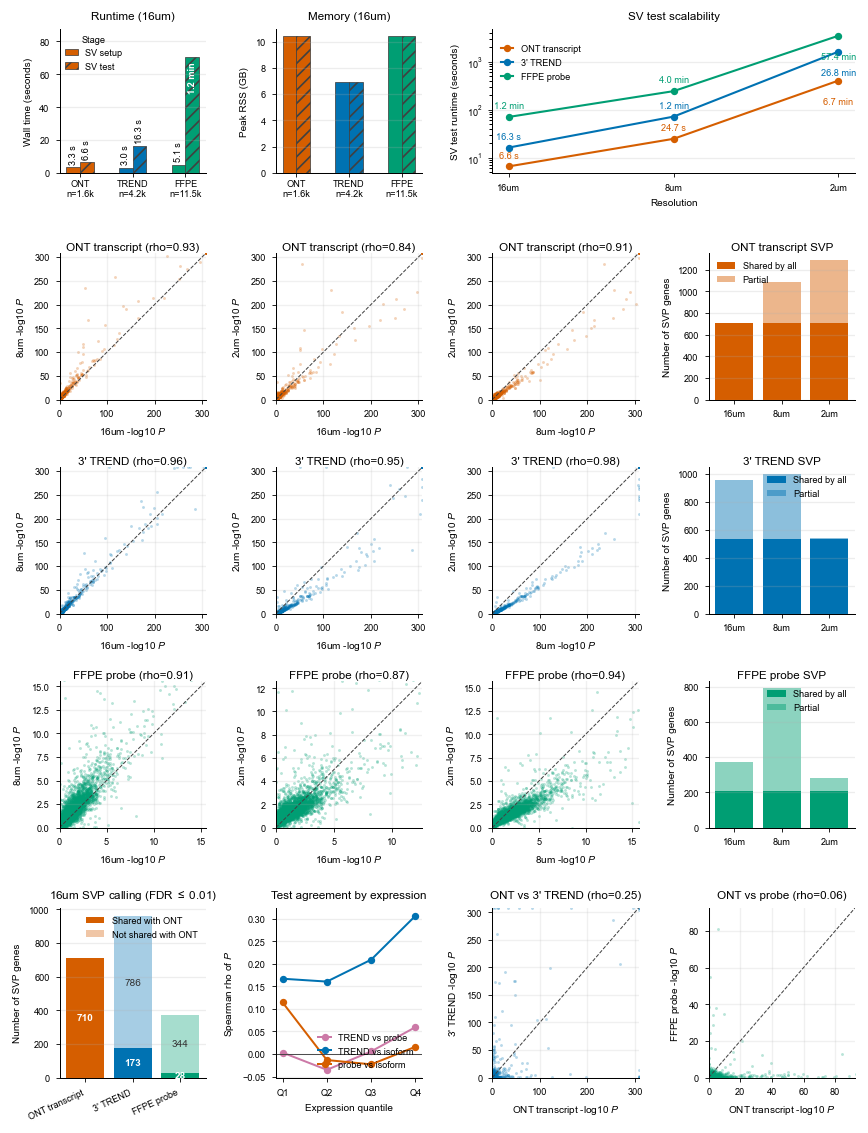

In [3]:
# Final SV figure: efficiency, cross-resolution agreement, and cross-platform agreement.

SV_PHASE_ORDER = ["data_prep", "sv_test"]
SV_PHASE_LABELS = {"data_prep": "SV setup", "sv_test": "SV test"}
SV_STAGE_HATCHES = {"data_prep": "", "sv_test": "///"}


def _fmt_runtime(seconds):
    if pd.isna(seconds):
        return ""
    seconds = float(seconds)
    if seconds < 1:
        return f"{seconds * 1000:.0f} ms"
    if seconds < 60:
        return f"{seconds:.1f} s"
    if seconds < 3600:
        return f"{seconds / 60:.1f} min"
    return f"{seconds / 3600:.1f} h"


def _rho(x, y):
    stat = spearmanr(x, y, nan_policy="omit")
    return float(stat.statistic if hasattr(stat, "statistic") else stat[0])


def _shared_gene_count(dataset_key):
    return sv_results[(dataset_key, "16um")]["gene_key"].nunique()


def _dataset_xtick_label(dataset_key):
    n = _shared_gene_count(dataset_key)
    short_labels = {"ont_tx": "ONT", "trend_3prime": "TREND", "ffpe_probe": "FFPE"}
    n_text = f"{n / 1000:.1f}k" if n is not None else "n/a"
    return (
        f"{short_labels.get(dataset_key, DATASET_LABELS.get(dataset_key, dataset_key))}\nn={n_text}"
    )


def _plot_stage_bars(ax, df16, value, ylabel, title, annotate_runtime=False, show_legend=False):
    dataset_keys = DATASET_ORDER
    phases = SV_PHASE_ORDER

    aggfunc = "sum" if value == "seconds" else "max"
    pivot = df16.pivot_table(
        index="dataset_key", columns="phase", values=value, aggfunc=aggfunc
    ).reindex(index=dataset_keys, columns=phases)

    x = np.arange(len(dataset_keys))
    width = min(0.26, 0.75 / max(1, len(phases)))
    for i, phase in enumerate(phases):
        offset = (i - (len(phases) - 1) / 2.0) * width
        values = pivot[phase].fillna(0)
        bars = ax.bar(
            x + offset,
            values,
            width=width,
            color=[DATASET_COLORS.get(key, "0.5") for key in dataset_keys],
            hatch=SV_STAGE_HATCHES.get(phase, ""),
            edgecolor="0.25",
            linewidth=0.45,
            label=SV_PHASE_LABELS.get(phase, phase),
        )
        if annotate_runtime:
            for bar, seconds in zip(bars, values, strict=True):
                if seconds > 0:
                    inside_bar = seconds >= np.nanmax(pivot.to_numpy(dtype=float)) * 0.65
                    ax.annotate(
                        _fmt_runtime(seconds),
                        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, -3 if inside_bar else 2),
                        textcoords="offset points",
                        ha="center",
                        va="top" if inside_bar else "bottom",
                        rotation=90,
                        fontsize=FONT_CONFIG["text"],
                        color="white" if inside_bar else "black",
                        fontweight="bold" if inside_bar else "normal",
                    )

    if annotate_runtime:
        ax.set_ylim(top=ax.get_ylim()[1] * 1.18)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels([_dataset_xtick_label(key) for key in dataset_keys], rotation=0, ha="center")
    ax.tick_params(axis="x", pad=1)
    ax.grid(axis="y", alpha=0.22)
    if show_legend:
        ax.legend(
            frameon=False,
            title="Stage",
            fontsize=FONT_CONFIG["text"],
            title_fontsize=FONT_CONFIG["legend"],
            loc="upper left",
            handlelength=1.4,
            borderaxespad=0.2,
        )


def _plot_sv_scalability(ax, sv_metrics):
    sv_scale = sv_metrics[
        sv_metrics["phase"].eq("sv_test") & sv_metrics["resolution"].isin(RESOLUTION_ORDER)
    ].copy()
    rx = np.arange(len(RESOLUTION_ORDER))
    for key in [key for key in DATASET_ORDER if key in set(sv_scale["dataset_key"])]:
        y = (
            sv_scale[sv_scale["dataset_key"].eq(key)]
            .groupby("resolution")["seconds"]
            .sum()
            .reindex(RESOLUTION_ORDER)
        )
        ax.plot(
            rx,
            y,
            marker="o",
            markersize=3.4,
            linewidth=1.25,
            color=DATASET_COLORS.get(key, "0.5"),
            label=DATASET_LABELS.get(key, key),
        )
        for xi, seconds in zip(rx, y, strict=True):
            if pd.notna(seconds):
                # Keep the high-resolution labels inside the axes and away from the title.
                y_offset = -10 if xi == len(RESOLUTION_ORDER) - 1 else 4
                va = "top" if y_offset < 0 else "bottom"
                ax.annotate(
                    _fmt_runtime(seconds),
                    xy=(xi, seconds),
                    xytext=(0, y_offset),
                    textcoords="offset points",
                    ha="center",
                    va=va,
                    fontsize=FONT_CONFIG["text"],
                    color=DATASET_COLORS.get(key, "0.5"),
                )
    positive = sv_scale["seconds"].dropna()
    if len(positive) and (positive > 0).all():
        ax.set_yscale("log")
    ax.set_title("SV test scalability", pad=6)
    ax.set_xlabel("Resolution")
    ax.set_ylabel("SV test runtime (seconds)")
    ax.set_xticks(rx)
    ax.set_xticklabels(RESOLUTION_ORDER)
    ax.grid(axis="y", alpha=0.22)
    ax.legend(
        frameon=False,
        fontsize=FONT_CONFIG["legend"],
        loc="upper left",
        bbox_to_anchor=(0.0, 0.95),
        handlelength=1.4,
    )


def _plot_resolution_scatter(ax, dataset_key, left_res, right_res):
    left = sv_results[(dataset_key, left_res)]
    right = sv_results[(dataset_key, right_res)]

    plot_df = (
        left[["gene_key", "pvalue"]]
        .rename(columns={"pvalue": "p_left"})
        .merge(
            right[["gene_key", "pvalue"]].rename(columns={"pvalue": "p_right"}),
            on="gene_key",
            how="inner",
        )
    )
    plot_df["x"] = minus_log10_p(plot_df["p_left"])
    plot_df["y"] = minus_log10_p(plot_df["p_right"])
    rho = _rho(plot_df["x"], plot_df["y"])
    lim = np.nanpercentile(plot_df[["x", "y"]].to_numpy(), 99.5)
    lim = max(1.0, float(lim))

    ax.scatter(
        plot_df["x"],
        plot_df["y"],
        s=3,
        alpha=0.28,
        color=DATASET_COLORS.get(dataset_key, "0.4"),
        linewidths=0,
        rasterized=True,
    )
    ax.plot([0, lim], [0, lim], color="0.25", linewidth=0.6, linestyle="--")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_title(f"{DATASET_LABELS.get(dataset_key, dataset_key)} (rho={rho:.2f})", pad=2)
    ax.set_box_aspect(1)
    ax.set_xlabel(f"{left_res} -log10 $P$")
    ax.set_ylabel(f"{right_res} -log10 $P$")
    ax.grid(alpha=0.18)


def _plot_resolution_counts(ax, dataset_key):
    svp_sets = {
        res: set(
            sv_results[(dataset_key, res)].loc[
                sv_results[(dataset_key, res)]["pvalue_adj"] <= FDR_THRESHOLD, "gene_key"
            ]
        )
        for res in RESOLUTION_ORDER
    }
    shared_three = set.intersection(*svp_sets.values())
    totals = [len(svp_sets[res]) for res in RESOLUTION_ORDER]
    shared = [len(svp_sets[res] & shared_three) for res in RESOLUTION_ORDER]
    other = [total - shared_i for total, shared_i in zip(totals, shared, strict=True)]

    x = np.arange(len(RESOLUTION_ORDER))
    color = DATASET_COLORS.get(dataset_key, "0.4")
    ax.bar(x, shared, color=color, alpha=1.0, label="Shared by all")
    ax.bar(x, other, bottom=shared, color=color, alpha=0.45, label="Partial")
    ax.set_title(f"{DATASET_LABELS.get(dataset_key, dataset_key)} SVP", pad=2)
    ax.set_box_aspect(1)
    ax.set_xticks(x)
    ax.set_xticklabels(RESOLUTION_ORDER)
    ax.set_ylabel("Number of SVP genes")
    ax.grid(axis="y", alpha=0.22)
    ax.legend(frameon=False, fontsize=FONT_CONFIG["legend"])


def _plot_ont_overlap(ax):
    svp_sets = {
        key: set(
            sv_results[(key, "16um")].loc[
                sv_results[(key, "16um")]["pvalue_adj"] <= FDR_THRESHOLD,
                "gene_key",
            ]
        )
        for key in DATASET_ORDER
    }
    ont_set = svp_sets["ont_tx"]
    shared_with_ont = []
    not_shared_with_ont = []
    for key in DATASET_ORDER:
        this = svp_sets[key]
        shared = this if key == "ont_tx" else this & ont_set
        shared_with_ont.append(len(shared))
        not_shared_with_ont.append(len(this - shared))

    x = np.arange(len(DATASET_ORDER))
    colors = [DATASET_COLORS.get(key, "0.5") for key in DATASET_ORDER]
    ax.bar(x, shared_with_ont, color=colors, alpha=1.0, label="Shared with ONT")
    ax.bar(
        x,
        not_shared_with_ont,
        bottom=shared_with_ont,
        color=colors,
        alpha=0.35,
        label="Not shared with ONT",
    )
    for xi, shared_n, other_n in zip(x, shared_with_ont, not_shared_with_ont, strict=True):
        if shared_n > 0:
            ax.text(
                xi,
                shared_n / 2,
                f"{shared_n}",
                ha="center",
                va="center",
                color="white",
                fontweight="bold",
            )
        if other_n > 0:
            ax.text(xi, shared_n + other_n / 2, f"{other_n}", ha="center", va="center", color="0.2")
    ax.set_title(f"16um SVP calling (FDR $\\leq$ {FDR_THRESHOLD})")
    ax.set_ylabel("Number of SVP genes")
    ax.set_xticks(x)
    ax.set_xticklabels(
        [DATASET_LABELS.get(key, key) for key in DATASET_ORDER], rotation=25, ha="right"
    )
    ax.grid(axis="y", alpha=0.22)
    ax.legend(frameon=False, fontsize=FONT_CONFIG["legend"])


def _plot_expression_agreement(ax):
    corr_plot = platform_corr.copy()
    if corr_plot.empty:
        raise ValueError("No cross-platform expression-agreement rows to plot.")
    corr_plot["pair"] = corr_plot["left"] + " vs " + corr_plot["right"]
    comparison_colors = {
        "3' TREND vs FFPE probe": "#CC79A7",
        "3' TREND vs ONT transcript": "#0072B2",
        "FFPE probe vs ONT transcript": "#D55E00",
    }
    comparison_labels = {
        "3' TREND vs FFPE probe": "TREND vs probe",
        "3' TREND vs ONT transcript": "TREND vs isoform",
        "FFPE probe vs ONT transcript": "probe vs isoform",
    }
    for pair, group in corr_plot.groupby("pair", sort=False):
        group = group.sort_values("expression_quantile")
        ax.plot(
            group["expression_quantile"],
            group["spearman_logp"],
            marker="o",
            markersize=3.4,
            linewidth=1.2,
            color=comparison_colors.get(pair, "0.4"),
            label=comparison_labels.get(pair, pair),
        )
    ax.set_title("Test agreement by expression")
    ax.set_xlabel("Expression quantile")
    ax.set_ylabel("Spearman rho of $P$")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"])
    ax.axhline(0, color="0.25", linewidth=0.55)
    ax.grid(axis="y", alpha=0.22)
    ax.legend(frameon=False, fontsize=FONT_CONFIG["legend"], loc="lower right", handlelength=1.4)


def _plot_platform_density(ax, left_key, right_key, title, cmap):
    left = sv_results[(left_key, "16um")]
    right = sv_results[(right_key, "16um")]
    plot_df = (
        left[["gene_key", "pvalue"]]
        .rename(columns={"pvalue": "p_left"})
        .merge(
            right[["gene_key", "pvalue"]].rename(columns={"pvalue": "p_right"}),
            on="gene_key",
            how="inner",
        )
    )
    plot_df["x"] = minus_log10_p(plot_df["p_left"])
    plot_df["y"] = minus_log10_p(plot_df["p_right"])
    rho = _rho(plot_df["x"], plot_df["y"])
    lim = np.nanpercentile(plot_df[["x", "y"]].to_numpy(), 99)
    lim = max(1.0, float(lim))
    ax.scatter(
        plot_df["x"],
        plot_df["y"],
        s=3,
        alpha=0.28,
        color=DATASET_COLORS.get(right_key, DATASET_COLORS.get(left_key, "0.4")),
        linewidths=0,
        rasterized=True,
    )
    ax.plot([0, lim], [0, lim], color="0.25", linewidth=0.6, linestyle="--")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_title(f"{title} (rho={rho:.2f})")
    ax.set_xlabel(f"{DATASET_LABELS.get(left_key, left_key)} -log10 $P$")
    ax.set_ylabel(f"{DATASET_LABELS.get(right_key, right_key)} -log10 $P$")
    ax.grid(alpha=0.18)


with plt.rc_context(
    {
        "font.size": FONT_CONFIG["font"],
        "axes.titlesize": FONT_CONFIG["title"],
        "axes.labelsize": FONT_CONFIG["label"],
        "xtick.labelsize": FONT_CONFIG["tick"],
        "ytick.labelsize": FONT_CONFIG["tick"],
        "legend.fontsize": FONT_CONFIG["legend"],
        "legend.title_fontsize": FONT_CONFIG["legend"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
):
    sv_metrics = metrics[metrics["phase"].isin(SV_PHASE_ORDER)].copy()
    sv_metrics["resolution"] = sv_metrics["resolution"].fillna("16um")
    sv16 = sv_metrics[sv_metrics["resolution"].eq("16um")].copy()

    fig = plt.figure(figsize=(MAX_FIGURE_WIDTH_IN, 9.6), constrained_layout=False)
    grid = fig.add_gridspec(
        7,
        4,
        height_ratios=[0.78, 0.01, 1.0, 1.0, 1.0, 0.01, 0.92],
        hspace=0.24,
        wspace=0.48,
    )
    fig.subplots_adjust(left=0.075, right=0.985, top=0.965, bottom=0.055)
    for spacer_row in [1, 5]:
        spacer_ax = fig.add_subplot(grid[spacer_row, :])
        spacer_ax.axis("off")

    _plot_stage_bars(
        fig.add_subplot(grid[0, 0]),
        sv16,
        value="seconds",
        ylabel="Wall time (seconds)",
        title="Runtime (16um)",
        annotate_runtime=True,
        show_legend=True,
    )
    _plot_stage_bars(
        fig.add_subplot(grid[0, 1]),
        sv16,
        value="max_rss_gb",
        ylabel="Peak RSS (GB)",
        title="Memory (16um)",
    )
    _plot_sv_scalability(fig.add_subplot(grid[0, 2:4]), sv_metrics)

    resolution_pairs = [("16um", "8um"), ("16um", "2um"), ("8um", "2um")]
    for row_idx, dataset_key in enumerate(DATASET_ORDER, start=2):
        for col_idx, (left_res, right_res) in enumerate(resolution_pairs):
            _plot_resolution_scatter(
                fig.add_subplot(grid[row_idx, col_idx]), dataset_key, left_res, right_res
            )
        _plot_resolution_counts(fig.add_subplot(grid[row_idx, 3]), dataset_key)

    _plot_ont_overlap(fig.add_subplot(grid[6, 0]))
    _plot_expression_agreement(fig.add_subplot(grid[6, 1]))
    _plot_platform_density(
        fig.add_subplot(grid[6, 2]), "ont_tx", "trend_3prime", "ONT vs 3' TREND", "Oranges"
    )
    _plot_platform_density(
        fig.add_subplot(grid[6, 3]), "ont_tx", "ffpe_probe", "ONT vs probe", "Greens"
    )

    save_pdf(fig, "svp_summary.pdf")
    plt.show()

## Check SVP genes shared by all platforms

In [4]:
shared_hits.head(5)

,priority_rank,gene_key,gene_trend_3prime,rank_trend_3prime,pvalue_trend_3prime,padj_trend_3prime,called_trend_3prime,gene_ffpe_probe,rank_ffpe_probe,pvalue_ffpe_probe,...,called_ont_tx,n_platforms_tested,n_platforms_called,called_platforms,sharing_class,min_pvalue,max_padj,mean_neglogp,mean_rank,called_all_three
0,1,mbp,Mbp,29.0,3.433207e-286,5.010114e-284,True,Mbp,19.0,2.586246e-41,...,True,3,3,3' TREND;FFPE probe;ONT transcript,triple,3.433207e-286,1.567265e-38,193.040664,21.333333,True
1,2,gabbr1,Gabbr1,16.0,0.000000e+00,0.000000e+00,True,Gabbr1,4.0,1.127522e-258,...,True,3,3,3' TREND;FFPE probe;ONT transcript,triple,0.000000e+00,3.369641e-33,199.800731,31.000000,True
2,3,pnkd,Pnkd,130.0,2.430939e-36,7.913640e-35,True,Pnkd,38.0,1.279965e-20,...,True,3,3,3' TREND;FFPE probe;ONT transcript,triple,2.430939e-36,3.878295e-18,25.473466,90.333333,True
3,4,arpp21,Arpp21,14.0,0.000000e+00,0.000000e+00,True,Arpp21,52.0,1.474232e-13,...,True,3,3,3' TREND;FFPE probe;ONT transcript,triple,0.000000e+00,3.264289e-11,134.926977,32.666667,True
4,5,gnas,Gnas,122.0,1.539277e-40,5.339523e-39,True,Gnas,25.0,2.916143e-35,...,True,3,3,3' TREND;FFPE probe;ONT transcript,triple,1.539277e-40,1.959561e-09,27.992147,111.333333,True


### Plot SVP gene spatial patterns

Spatial plotting helpers are imported from scripts.splisosm_visiumhd_cbs.plotting. Available here for custom cells: `orient_spatial_image` and `feature_names_for_gene`.

In [5]:
def ensure_rasterized_subset(sdata, bins, table_name, layer="counts"):
    raster_key = f"rasterized_{table_name}_{layer}"
    if raster_key in sdata.images:
        return raster_key
    adata = sdata.tables[table_name]
    adata.X = adata.layers[layer] if layer in adata.layers else adata.X
    if hasattr(adata.X, "tocsc") and getattr(adata.X, "format", None) != "csc":
        adata.X = adata.X.tocsc()
    sdata[raster_key] = rasterize_bins(
        sdata,
        bins=bins,
        table_name=table_name,
        col_key="array_col",
        row_key="array_row",
    )
    return raster_key

In [6]:
# Load all three sdata and lazy-rasterize the tables for plotting.
sdata_cache = {}

for key in DATASETS.keys():
    _cfg = DATASETS[key]
    sdata = load_sdata(_cfg)
    table_cfg = resolve_table_config(_cfg, sdata, "16um")
    adata = sdata.tables[table_cfg["table_name"]]
    raster_key = ensure_rasterized_subset(
        sdata, bins=table_cfg["bins"], table_name=table_cfg["table_name"]
    )
    sdata_cache[key] = {
        "sdata": sdata,
        "adata": adata,
        "table_cfg": table_cfg,
        "raster_key": raster_key,
    }

#### Custom gene inspection


['ENSMUST00000111872', 'ENSMUST00000161467', 'ENSMUST00000159183', 'ENSMUST00000172380', 'ENSMUST00000160741']
['Arpp21:chr9:111894282-111894720:-1', 'Arpp21:chr9:112010071-112010437:-1', 'Arpp21:chr9:112011131-112011539:-1', 'Arpp21:chr9:112011809-112016709:-1']
['Arpp21|51fb716', 'Arpp21|74ea103', 'Arpp21|8f2f379']


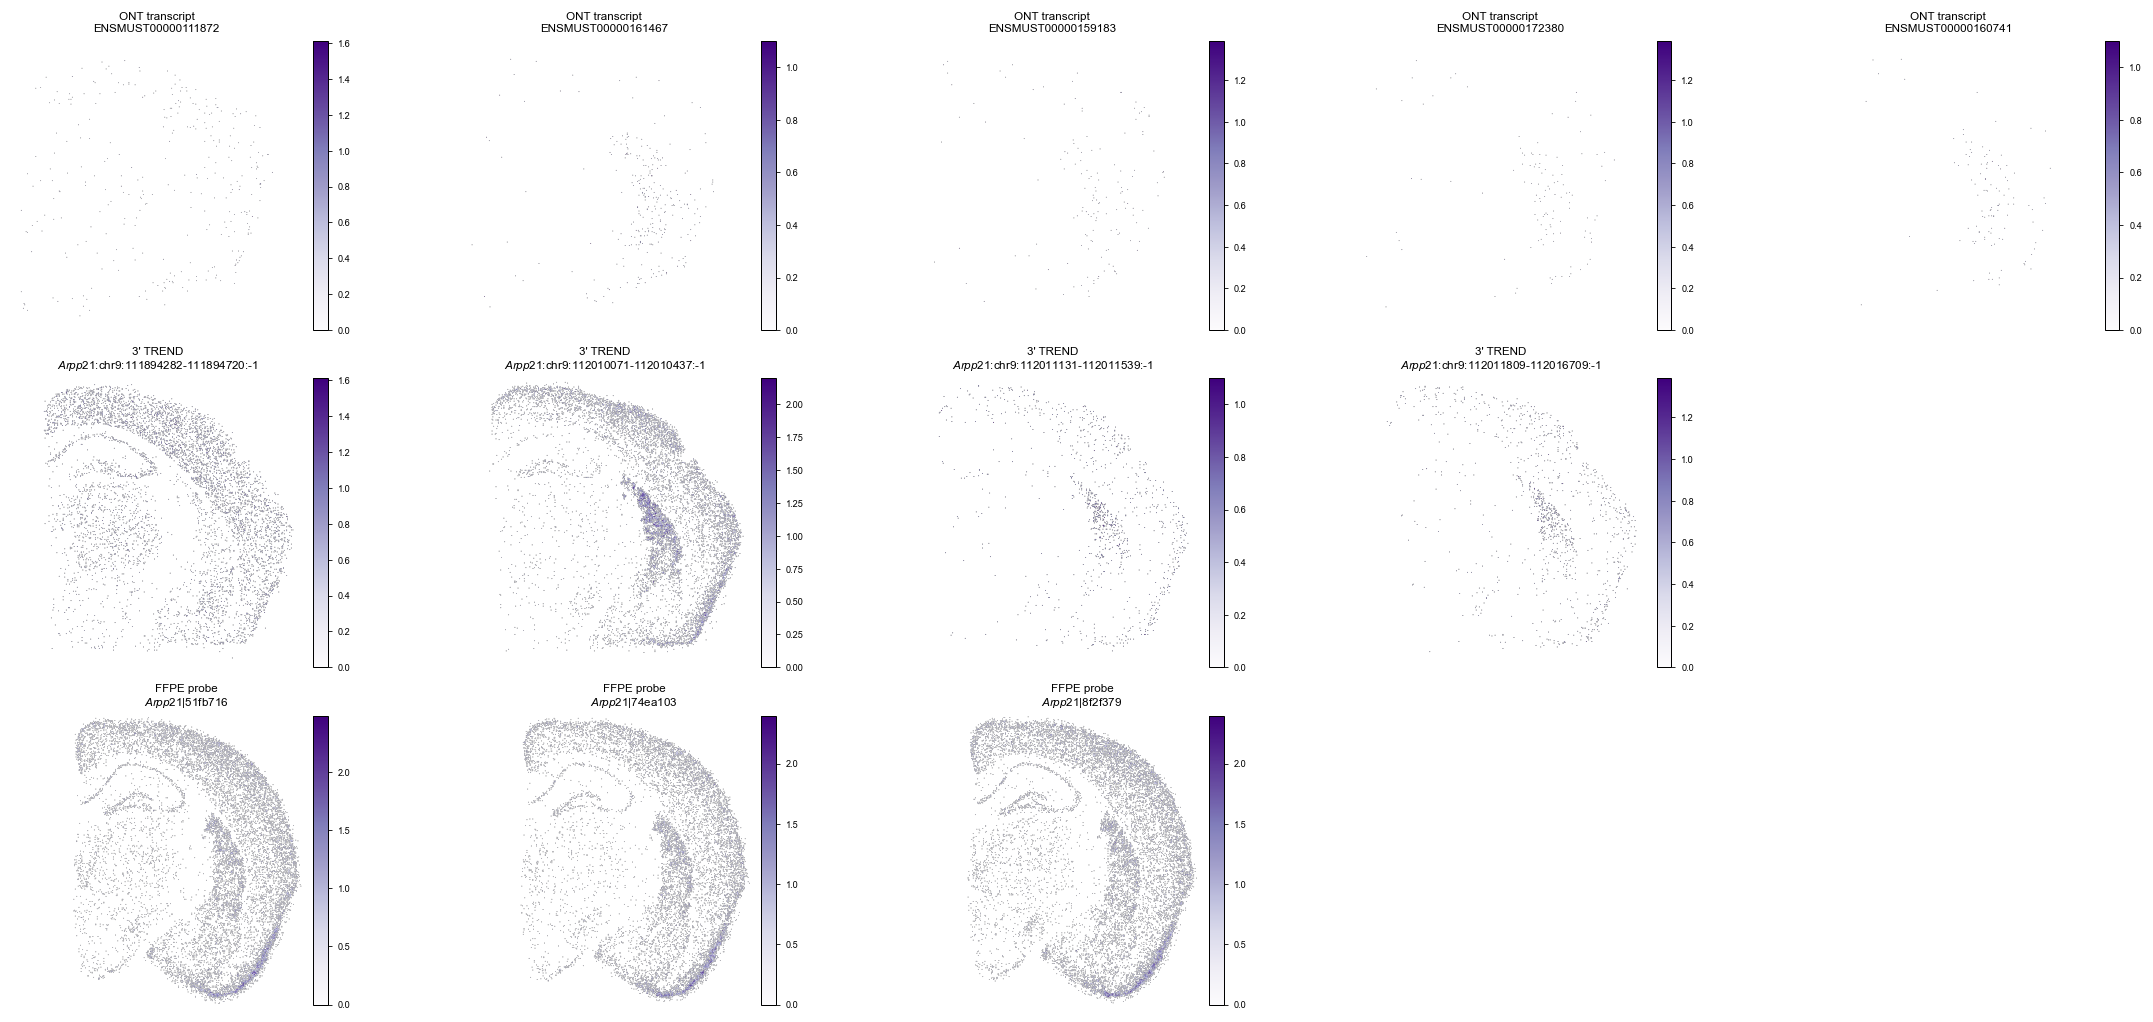

In [7]:
_gene_to_plot = "Arpp21"
_features = {}
for _dataset in DATASET_ORDER:
    _features[_dataset] = feature_names_for_gene(
        sdata_cache[_dataset]["adata"], sdata_cache[_dataset]["table_cfg"], _gene_to_plot
    )
    print(_features[_dataset])

ncols = max(len(f) for f in _features.values())
fig, axes = plt.subplots(len(DATASET_ORDER), ncols, figsize=(3.75 * ncols, 8.5), squeeze=False)

for row, dataset_key in enumerate(DATASET_ORDER):
    features = _features[dataset_key][:ncols]
    data = (
        sdata_cache[dataset_key]["sdata"][sdata_cache[dataset_key]["raster_key"]]
        .sel(c=features)
        .values
    )
    counts_cube = np.moveaxis(np.asarray(data, dtype=float), 0, -1)

    for col in range(ncols):
        ax = axes[row, col]

        if col >= len(features):
            ax.axis("off")
            continue

        c = counts_cube[:, :, col]
        c = np.where(c == 0, np.nan, c)
        c = orient_spatial_image(c, dataset_key)

        im = ax.imshow(np.log1p(c), cmap="Purples", vmin=0.0)
        ax.set_title(
            f"{DATASET_LABELS.get(dataset_key, dataset_key)}\n"
            + gene_feature_label(features[col], _gene_to_plot)
        )
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

fig.tight_layout()
plt.show()

#### *Mbp* with selected features

In [8]:
for _dataset in DATASET_ORDER:
    _gene_to_plot = "Mbp"
    features = feature_names_for_gene(
        sdata_cache[_dataset]["adata"], sdata_cache[_dataset]["table_cfg"], _gene_to_plot
    )
    print(features)

['ENSMUST00000133193', 'ENSMUST00000142850', 'ENSMUST00000080658', 'ENSMUST00000047865', 'ENSMUST00000091789']
['Mbp:chr18:82603362-82603640:1', 'Mbp:chr18:82602714-82603715:1', 'Mbp:chr18:82572314-82602582:1', 'Mbp:chr18:82576438-82576816:1', 'Mbp:chr18:82596984-82597242:1']
['Mbp|c05e63e', 'Mbp|bd2feaf', 'Mbp|fd67b23', 'Mbp|d733086', 'Mbp|e63e611']


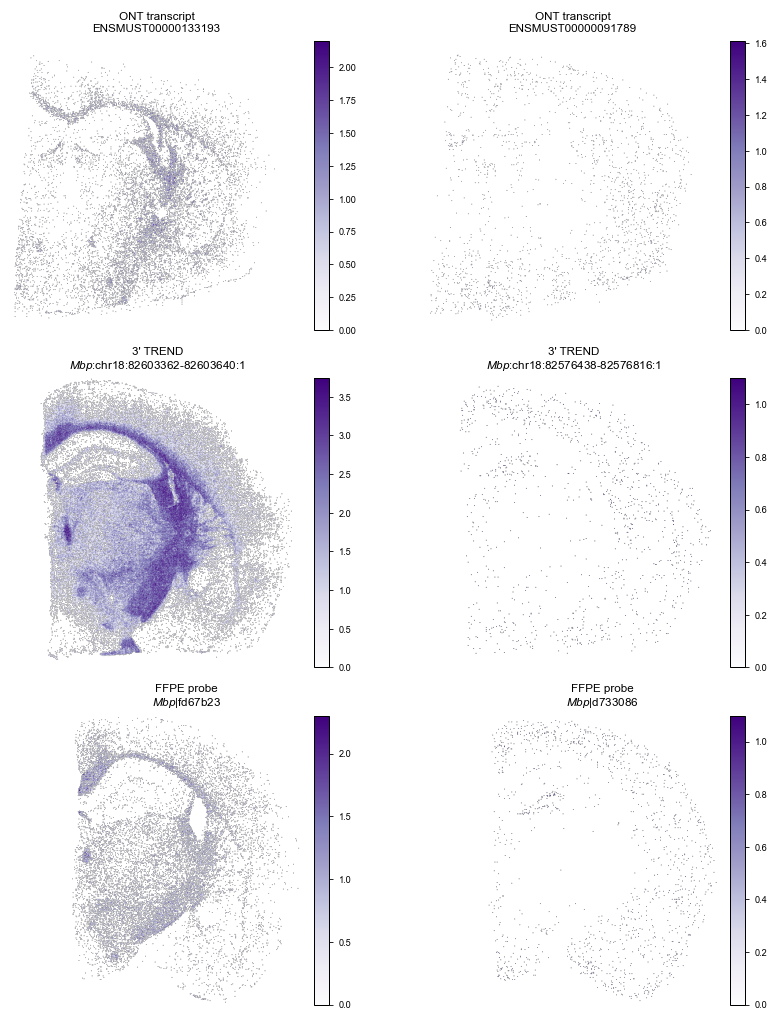

In [9]:
mbp_features = {
    "ffpe_probe": ["Mbp|fd67b23", "Mbp|d733086"],
    "trend_3prime": ["Mbp:chr18:82603362-82603640:1", "Mbp:chr18:82576438-82576816:1"],
    "ont_tx": ["ENSMUST00000133193", "ENSMUST00000091789"],
}
ncols = max(len(f) for f in mbp_features.values())
fig, axes = plt.subplots(len(DATASET_ORDER), ncols, figsize=(3.75 * ncols, 8.5), squeeze=False)

for row, dataset_key in enumerate(DATASET_ORDER):
    features = mbp_features.get(dataset_key, [])[:ncols]
    data = (
        sdata_cache[dataset_key]["sdata"][sdata_cache[dataset_key]["raster_key"]]
        .sel(c=features)
        .values
    )
    counts_cube = np.moveaxis(np.asarray(data, dtype=float), 0, -1)

    for col in range(ncols):
        ax = axes[row, col]

        if col >= len(features):
            ax.axis("off")
            continue

        c = counts_cube[:, :, col]
        c = np.where(c == 0, np.nan, c)
        c = orient_spatial_image(c, dataset_key)

        im = ax.imshow(np.log1p(c), cmap="Purples", vmin=0.0)
        ax.set_title(
            f"{DATASET_LABELS.get(dataset_key, dataset_key)}\n"
            + gene_feature_label(features[col], _gene_to_plot)
        )
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

fig.tight_layout()
plt.show()

#### *Gabbr1* with selected features

In [10]:
for _dataset in DATASET_ORDER:
    _gene_to_plot = "Gabbr1"
    features = feature_names_for_gene(
        sdata_cache[_dataset]["adata"], sdata_cache[_dataset]["table_cfg"], _gene_to_plot
    )
    print(features)

['ENSMUST00000025338', 'ENSMUST00000172789', 'ENSMUST00000172792', 'ENSMUST00000174456']
['Gabbr1:chr17:37384814-37385168:1', 'Gabbr1:chr17:37359962-37360382:1', 'Gabbr1:chr17:37383084-37384076:1', 'Gabbr1:chr17:37359590-37359938:1', 'Gabbr1:chr17:37384409-37384781:1']
['Gabbr1|087d0c3', 'Gabbr1|343eef1', 'Gabbr1|ccb3aab', 'Gabbr1|ee99a08', 'Gabbr1|1eb1072']


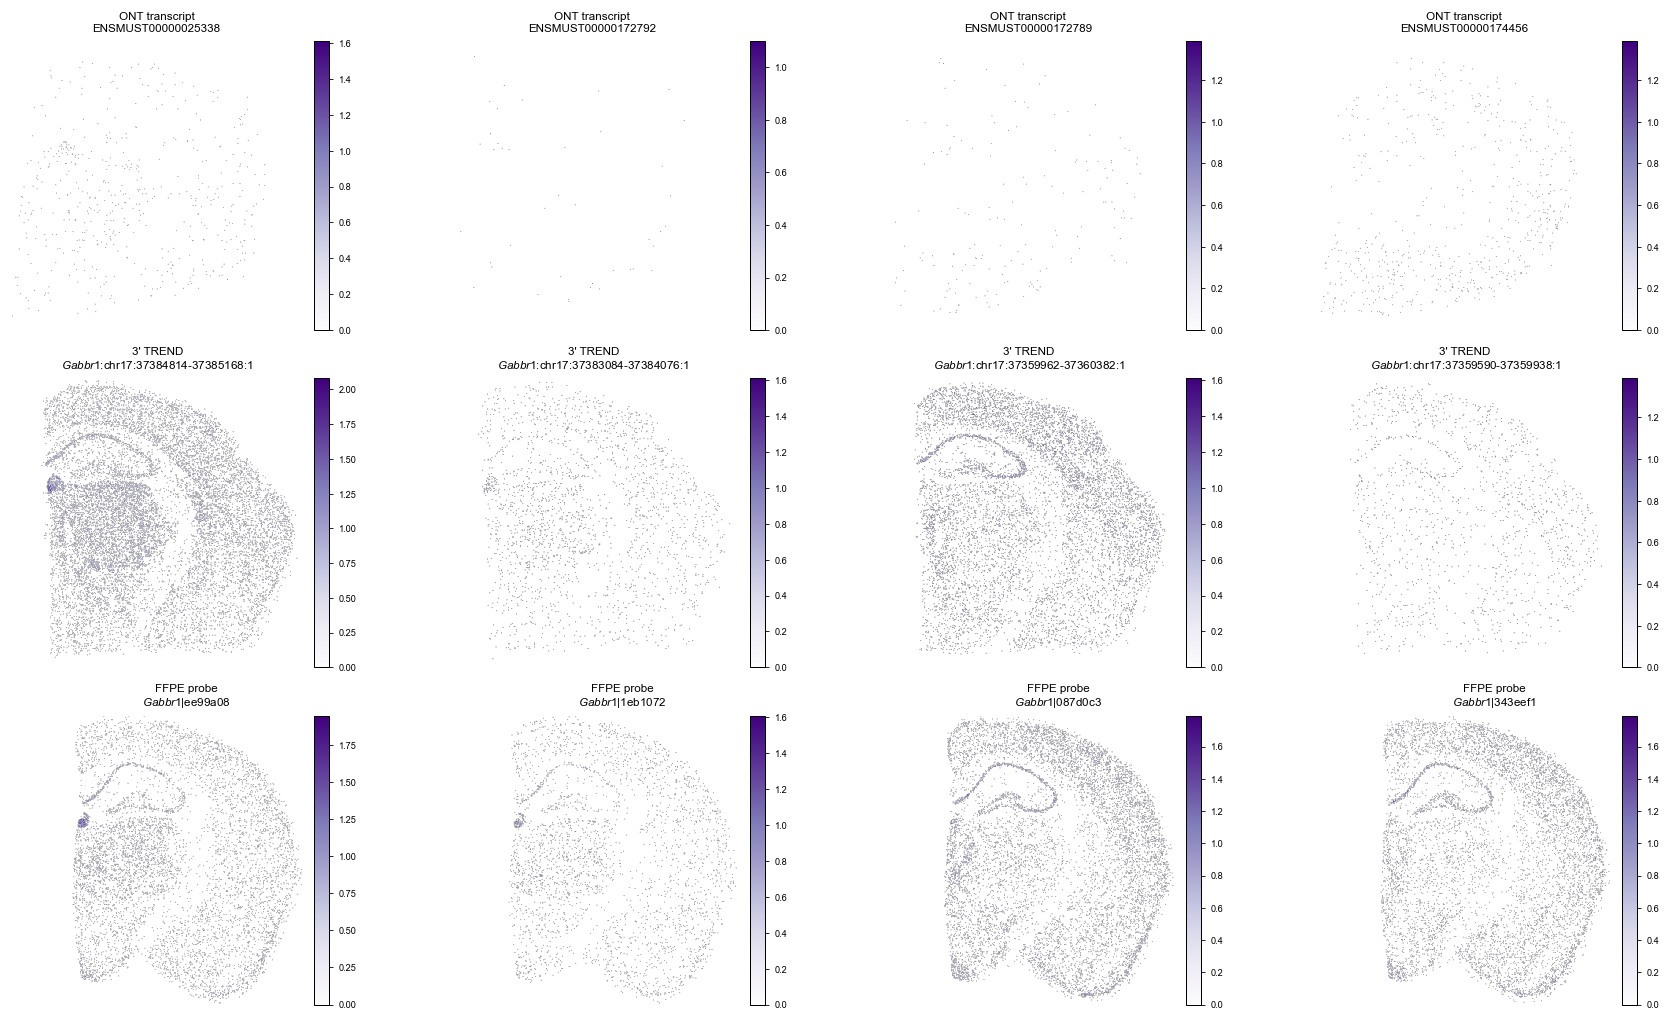

In [11]:
gabbr1_features = {
    "ffpe_probe": ["Gabbr1|ee99a08", "Gabbr1|1eb1072", "Gabbr1|087d0c3", "Gabbr1|343eef1"],
    "trend_3prime": [
        "Gabbr1:chr17:37384814-37385168:1",
        "Gabbr1:chr17:37383084-37384076:1",
        "Gabbr1:chr17:37359962-37360382:1",
        "Gabbr1:chr17:37359590-37359938:1",
    ],
    "ont_tx": [
        "ENSMUST00000025338",
        "ENSMUST00000172792",
        "ENSMUST00000172789",
        "ENSMUST00000174456",
    ],
}
ncols = max(len(f) for f in gabbr1_features.values())
fig, axes = plt.subplots(len(DATASET_ORDER), ncols, figsize=(3.75 * ncols, 8.5), squeeze=False)

for row, dataset_key in enumerate(DATASET_ORDER):
    features = gabbr1_features.get(dataset_key, [])[:ncols]
    data = (
        sdata_cache[dataset_key]["sdata"][sdata_cache[dataset_key]["raster_key"]]
        .sel(c=features)
        .values
    )
    counts_cube = np.moveaxis(np.asarray(data, dtype=float), 0, -1)

    for col in range(ncols):
        ax = axes[row, col]

        if col >= len(features):
            ax.axis("off")
            continue

        c = counts_cube[:, :, col]
        c = np.where(c == 0, np.nan, c)
        c = orient_spatial_image(c, dataset_key)

        im = ax.imshow(np.log1p(c), cmap="Purples", vmin=0.0)
        ax.set_title(
            f"{DATASET_LABELS.get(dataset_key, dataset_key)}\n"
            + gene_feature_label(features[col], _gene_to_plot)
        )
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

fig.tight_layout()
plt.show()

### Transcript and event structure visualization

In [12]:
# Load reference feature structures once; reuse the cache for all structure plots.
reference_cache = load_reference_feature_cache()
feature_cache_summary = pd.DataFrame(
    [
        {"source": "reference transcripts", "entries": len(reference_cache["reference"]["by_tx"])},
        {"source": "ONT transcripts", "entries": len(reference_cache["ont"]["by_input"])},
        {"source": "FFPE probes", "entries": len(reference_cache["probe"])},
        {"source": "3' TREND peaks", "entries": len(reference_cache["trend"])},
    ]
)
display(feature_cache_summary)

,source,entries
0,reference transcripts,149488
1,ONT transcripts,227783
2,FFPE probes,55480
3,3' TREND peaks,20722


#### *Mbp*

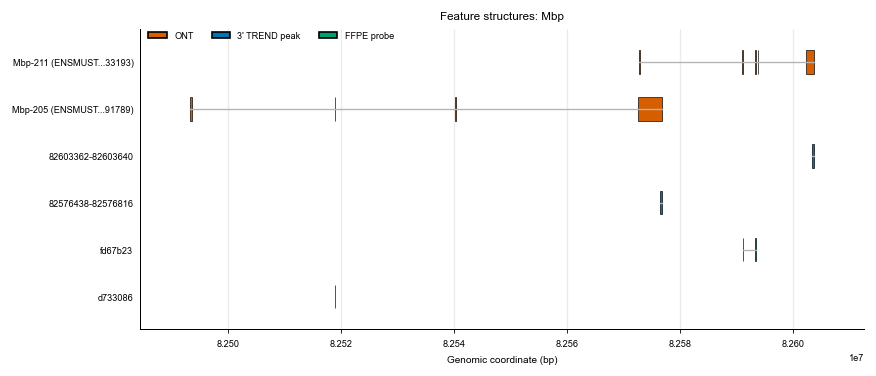

In [13]:
# with selected features
fig = plot_feature_structure(
    "Mbp",
    reference_cache,
    sdata_cache=sdata_cache,
    include_reference=False,
    ont_tx_list=mbp_features["ont_tx"],
    probe_list=mbp_features["ffpe_probe"],
    trend_list=mbp_features["trend_3prime"],
)
plt.show()

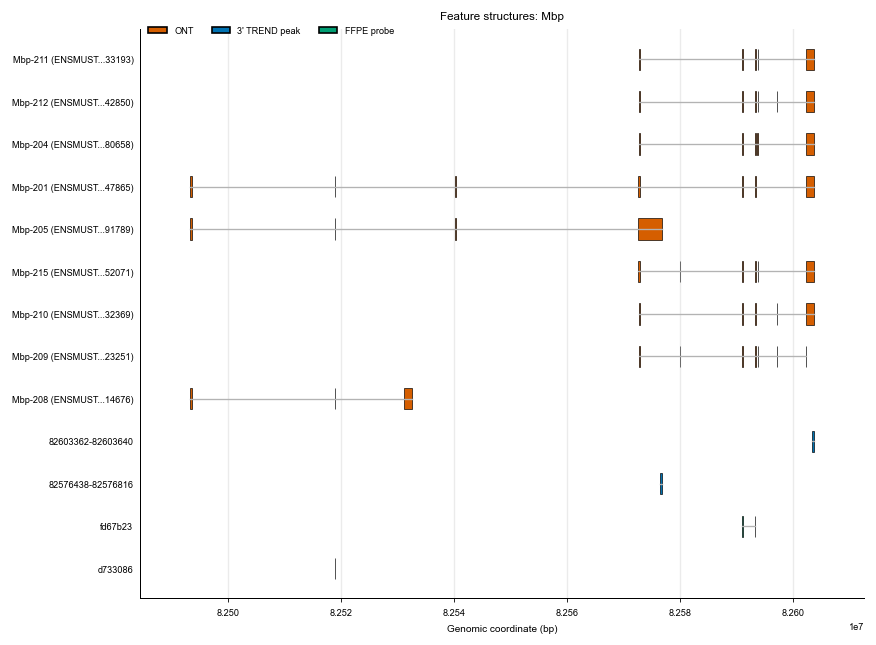

In [14]:
# with all detected ONT transcripts
fig = plot_feature_structure(
    "Mbp",
    reference_cache,
    sdata_cache=sdata_cache,
    include_reference=False,
    ont_tx_list=None,
    probe_list=mbp_features["ffpe_probe"],
    trend_list=mbp_features["trend_3prime"],
)
plt.show()

#### *Gabbr1*

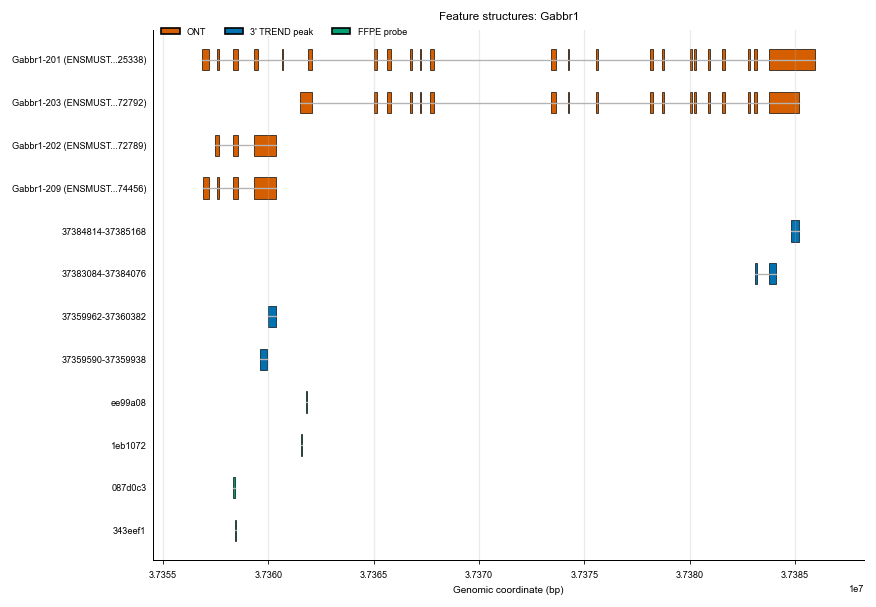

In [15]:
# with selected features
fig = plot_feature_structure(
    "Gabbr1",
    reference_cache,
    sdata_cache=sdata_cache,
    include_reference=False,
    ont_tx_list=gabbr1_features["ont_tx"],
    probe_list=gabbr1_features["ffpe_probe"],
    trend_list=gabbr1_features["trend_3prime"],
)
plt.show()

## DU test summary figure + *Mbp* example

This section builds a DU test (TFs and RBPs x all SVP per dataset, 16um) supplementary figure from cached workflow outputs and saves it as one PDF. *Mbp* is highlighted with the selected TF candidates *Myt1l*, *Egr1*, and *Sox10*, including their expression maps, DU associations, and ReMap binding tracks.


wrote /Users/jysumac/Projects/sonic-paper/figures/splisosm_visiumhd_cbs/mbp_du_regulator_summary.pdf


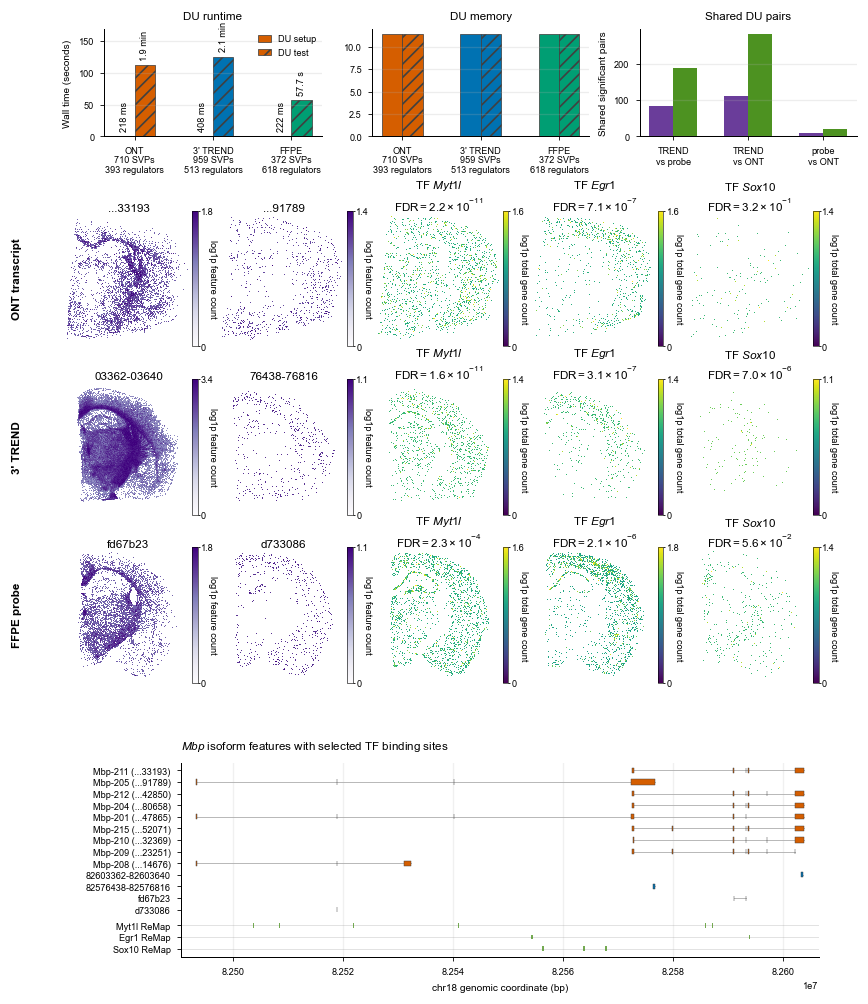

In [16]:
# Final Mbp DU/regulator figure assembled from cached DU tables and SpatialData rasters.

DU_PHASE_ORDER = ["du_setup", "du_test"]
DU_PHASE_LABELS = {"du_setup": "DU setup", "du_test": "DU test"}
DU_STAGE_HATCHES = {"du_setup": "", "du_test": "///"}
DU_COVARIATE_SETS = ["rbp", "tf_chip"]
DU_COVARIATE_LABELS = {"rbp": "RBP", "tf_chip": "TF"}
DU_COVARIATE_COLORS = {"rbp": "#6A3D9A", "tf_chip": "#4D9221"}
MBP_EXAMPLE_TFS = ("Myt1l", "Egr1", "Sox10")
MBP_SELECTED_FEATURES = {
    "ffpe_probe": ["Mbp|fd67b23", "Mbp|d733086"],
    "trend_3prime": ["Mbp:chr18:82603362-82603640:1", "Mbp:chr18:82576438-82576816:1"],
    "ont_tx": ["ENSMUST00000133193", "ENSMUST00000091789"],
}


def _fmt_runtime(seconds):
    if pd.isna(seconds):
        return ""
    seconds = float(seconds)
    if seconds < 1:
        return f"{seconds * 1000:.0f} ms"
    if seconds < 60:
        return f"{seconds:.1f} s"
    if seconds < 3600:
        return f"{seconds / 60:.1f} min"
    return f"{seconds / 3600:.1f} h"


def _du_metric_table():
    du_metrics = metrics[metrics["phase"].isin(DU_PHASE_ORDER)].copy()
    if du_metrics.empty:
        raise ValueError("No DU runtime metrics found in runtime_memory_metrics.csv.")
    return du_metrics


def _du_result_set(covariate_set):
    return du_tf_results if covariate_set == "tf_chip" else du_rbp_results


def _du_shared_table(covariate_set):
    return du_tf_shared_assoc if covariate_set == "tf_chip" else du_rbp_shared_assoc


def _du_agreement_table(covariate_set):
    return du_tf_agreement if covariate_set == "tf_chip" else du_rbp_agreement


def _du_metric_value(dataset_key, du_metrics, column):
    group = du_metrics[du_metrics["dataset_key"].eq(dataset_key)]
    value = pd.to_numeric(group[column], errors="coerce").max()
    if pd.isna(value):
        raise ValueError(f"No {column!r} DU metric for {dataset_key!r}.")
    return int(value)


def _du_xtick_label(dataset_key, du_metrics):
    n_svp = _du_metric_value(dataset_key, du_metrics, "n_svp_genes")
    n_regulators = _du_metric_value(dataset_key, du_metrics, "n_covariates")
    short_labels = {"ont_tx": "ONT", "trend_3prime": "3' TREND", "ffpe_probe": "FFPE"}
    return f"{short_labels.get(dataset_key, dataset_key)}\n{n_svp} SVPs\n{n_regulators} regulators"


def _plot_du_stage_bars(
    ax, du_metrics, value, ylabel, title, annotate_runtime=False, show_legend=False
):
    dataset_keys = DATASET_ORDER
    phases = DU_PHASE_ORDER

    aggfunc = "sum" if value == "seconds" else "max"
    grouped = du_metrics.groupby(["dataset_key", "phase"], as_index=False)[value].agg(aggfunc)
    x = np.arange(len(dataset_keys))
    width = min(0.26, 0.72 / max(1, len(phases)))

    for i, phase in enumerate(phases):
        values = []
        for dataset_key in dataset_keys:
            match = grouped[grouped["dataset_key"].eq(dataset_key) & grouped["phase"].eq(phase)]
            values.append(float(match[value].iloc[0]) if not match.empty else 0.0)
        offset = (i - (len(phases) - 1) / 2.0) * width
        bars = ax.bar(
            x + offset,
            values,
            width=width,
            color=[DATASET_COLORS.get(dataset_key, "0.5") for dataset_key in dataset_keys],
            hatch=DU_STAGE_HATCHES.get(phase, ""),
            edgecolor="0.25",
            linewidth=0.45,
            label=DU_PHASE_LABELS.get(phase, phase),
        )
        if annotate_runtime:
            for bar, seconds in zip(bars, values, strict=False):
                if seconds > 0:
                    ax.annotate(
                        _fmt_runtime(seconds),
                        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        rotation=90,
                        fontsize=FONT_CONFIG["text"],
                    )
    if annotate_runtime:
        ax.set_ylim(top=ax.get_ylim()[1] * 1.28)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(
        [_du_xtick_label(key, du_metrics) for key in dataset_keys],
        fontsize=FONT_CONFIG["tick"],
        linespacing=1.05,
    )
    ax.grid(axis="y", alpha=0.22)
    if show_legend:
        ax.legend(
            frameon=False,
            fontsize=FONT_CONFIG["legend"],
            loc="upper right",
            handlelength=1.4,
            borderaxespad=0.2,
        )


def _combined_agreement():
    rows = []
    for covariate_set in DU_COVARIATE_SETS:
        df = _du_agreement_table(covariate_set)
        if df.empty:
            raise ValueError(f"No DU agreement rows for {covariate_set!r}.")
        tmp = df.copy()
        tmp["covariate_set"] = covariate_set
        tmp["pair"] = tmp["left"] + " vs " + tmp["right"]
        rows.append(tmp)
    return pd.concat(rows, ignore_index=True, sort=False)


def _short_du_pair_label(pair):
    return {
        "3' TREND vs FFPE probe": "TREND\nvs probe",
        "3' TREND vs ONT transcript": "TREND\nvs ONT",
        "FFPE probe vs ONT transcript": "probe\nvs ONT",
    }.get(pair, pair.replace(" vs ", "\nvs "))


def _plot_du_agreement(ax):
    plot_df = _combined_agreement()
    pair_order = plot_df["pair"].drop_duplicates().tolist()
    x = np.arange(len(pair_order))
    width = 0.32
    for i, covariate_set in enumerate(DU_COVARIATE_SETS):
        group = plot_df[plot_df["covariate_set"].eq(covariate_set)].set_index("pair")
        y = [group["spearman_logp"].get(pair, np.nan) for pair in pair_order]
        ax.bar(
            x + (i - 0.5) * width,
            y,
            width=width,
            color=DU_COVARIATE_COLORS[covariate_set],
            label=DU_COVARIATE_LABELS[covariate_set],
        )
    ax.axhline(0, color="0.25", linewidth=0.6)
    ax.set_title("DU $P$ rho")
    ax.set_ylim(top=ax.get_ylim()[1] * 1.20)
    ax.set_ylabel("Spearman rho of -log10 $P$")
    ax.set_xticks(x)
    ax.set_xticklabels([_short_du_pair_label(pair) for pair in pair_order], rotation=0, ha="center")
    ax.grid(axis="y", alpha=0.22)
    ax.legend(
        frameon=False,
        fontsize=FONT_CONFIG["legend"],
        loc="upper right",
        handlelength=1.2,
        borderaxespad=0.2,
    )


def _plot_du_sig_overlap(ax):
    plot_df = _combined_agreement()
    pair_order = plot_df["pair"].drop_duplicates().tolist()
    x = np.arange(len(pair_order))
    width = 0.32
    for i, covariate_set in enumerate(DU_COVARIATE_SETS):
        group = plot_df[plot_df["covariate_set"].eq(covariate_set)].set_index("pair")
        y = [group["shared_sig_pairs"].get(pair, np.nan) for pair in pair_order]
        ax.bar(
            x + (i - 0.5) * width,
            y,
            width=width,
            color=DU_COVARIATE_COLORS[covariate_set],
            label=DU_COVARIATE_LABELS[covariate_set],
        )
    ax.set_title("Shared DU pairs")
    ax.set_ylabel("Shared significant pairs")
    ax.set_xticks(x)
    ax.set_xticklabels([_short_du_pair_label(pair) for pair in pair_order], rotation=0, ha="center")
    ax.grid(axis="y", alpha=0.22)


def _association_label(row, prefix):
    for key in ["ont_tx", "trend_3prime", "ffpe_probe"]:
        col = f"{prefix}_{key}"
        if col in row and pd.notna(row[col]):
            return str(row[col])
    return str(row.get(f"{prefix}_key", ""))


def _mbp_associations(covariate_set, top_n=5):
    table = _du_shared_table(covariate_set)
    mbp = table[table["gene_key"].eq("mbp")].copy()
    if mbp.empty:
        raise ValueError(f"No Mbp shared DU associations for {covariate_set!r}.")
    return mbp.sort_values(
        ["sig_all", "max_padj", "mean_neglogp"], ascending=[False, True, False]
    ).head(top_n)


def _mbp_example_associations(covariate_set, example_gene, top_n=5):
    """Place a hand-picked Mbp regulator first, then fill with DU-ranked hits."""
    mbp = _mbp_associations(covariate_set, top_n=200)
    example_key = normalize_gene_symbol(example_gene)
    example = mbp[mbp["covariate_key"].eq(example_key)].head(1)
    if example.empty:
        raise ValueError(f"Mbp example regulator {example_gene!r} was not found.")
    remainder = mbp[~mbp["covariate_key"].eq(example_key)].head(max(0, top_n - 1))
    return pd.concat([example, remainder], ignore_index=True, sort=False)


def _top_regulator_label(top_df):
    return _association_label(top_df.iloc[0], "covariate")


def _format_fdr(value):
    mantissa, exponent = f"{float(value):.1e}".split("e")
    return rf"$\mathrm{{FDR}}={mantissa}\times10^{{{int(exponent)}}}$"


def _mbp_du_fdr_label(gene, dataset_key):
    df = du_regulator_results[dataset_key]
    hit = df[df["gene_key"].eq("mbp") & df["covariate_key"].eq(normalize_gene_symbol(gene))]
    if hit.empty:
        return "not tested"
    return _format_fdr(hit["pvalue_adj"].iloc[0])


def _plot_mbp_regulator_bar(ax, top_mbp, title, show_legend=False):
    labels = [_association_label(row, "covariate") for _, row in top_mbp.iterrows()]
    y = np.arange(top_mbp.shape[0])
    height = 0.22
    xmax = 0.0
    for i, key in enumerate(DATASET_ORDER):
        col = f"pvalue_adj_{key}"
        values = (
            minus_log10_p(top_mbp[col]) if col in top_mbp else np.repeat(np.nan, top_mbp.shape[0])
        )
        xmax = max(xmax, float(np.nanmax(values)))
        ax.barh(
            y + (i - 1) * height,
            values,
            height=height,
            color=DATASET_COLORS.get(key, "0.5"),
            alpha=0.86,
            label=DATASET_LABELS.get(key, key),
        )
    threshold = float(minus_log10_p([FDR_THRESHOLD])[0])
    ax.axvline(threshold, color="0.25", linestyle="--", linewidth=0.7)
    ax.set_title(title)
    ax.set_xlabel(r"$-\log_{10}(\mathrm{FDR})$ (DU)", labelpad=2)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    for i, tick in enumerate(ax.get_yticklabels()):
        tick.set_fontstyle("italic")
        if i == 0:
            tick.set_fontweight("bold")
    ax.set_xlim(0, max(1.0, xmax * 1.08))
    ax.text(
        threshold + 0.15,
        0.03,
        r"FDR $\leq 0.01$",
        transform=ax.get_xaxis_transform(),
        ha="left",
        va="bottom",
        fontsize=FONT_CONFIG["text"],
        color="0.25",
    )
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.22)
    if show_legend:
        ax.legend(
            frameon=False,
            fontsize=FONT_CONFIG["text"],
            loc="upper right",
            bbox_to_anchor=(1.0, 1.16),
            ncol=3,
            columnspacing=0.65,
            handlelength=1.2,
            borderaxespad=0.0,
        )


def _short_feature_label(feature):
    feature = str(feature)
    if feature.startswith("ENSMUST"):
        return f"...{feature[-5:]}"
    if "|" in feature:
        return feature.split("|")[-1]
    parts = feature.split(":")
    if len(parts) >= 4:
        return parts[2]
    return feature


def _collect_mbp_map_records(tf_labels):
    records = []
    for key in DATASET_ORDER:
        for slot, feature in enumerate(MBP_SELECTED_FEATURES[key][:2]):
            image, label = spatial_feature_image(sdata_cache, key, feature)
            records.append(
                {
                    "dataset_key": key,
                    "slot": slot,
                    "title": label,
                    "image": image,
                    "cmap": "Purples",
                    "cbar_label": "log1p feature count",
                    "show_cbar_label": key == "ffpe_probe" and slot == 0,
                    "gamma": 0.38,
                    "dilate": True,
                }
            )
        for offset, gene in enumerate(tf_labels):
            image, _ = spatial_gene_expression_image(sdata_cache, key, gene, max_features=None)
            title = rf"TF $\mathit{{{gene}}}$" + f"\n{_mbp_du_fdr_label(gene, key)}"
            records.append(
                {
                    "dataset_key": key,
                    "slot": 2 + offset,
                    "title": title,
                    "image": image,
                    "cmap": "viridis",
                    "cbar_label": "log1p total gene count",
                    "show_cbar_label": key == "ffpe_probe" and offset == 0,
                    "gamma": 0.55,
                }
            )
    return records


def _plot_map_axis(fig, ax, cax, record, target_shape, *, dataset_label=False):
    image = pad_spatial_image_to_shape(record.get("prepared_image"), target_shape)
    from matplotlib.colors import PowerNorm

    cmap = plt.get_cmap(record["cmap"]).copy()
    cmap.set_bad("white")
    positive = image[np.isfinite(image) & (image > 0)]
    vmax = float(np.nanpercentile(positive, 99.5)) if len(positive) else 1.0
    vmax = max(vmax, 0.25)
    im = ax.imshow(
        image,
        cmap=cmap,
        norm=PowerNorm(gamma=record.get("gamma", 0.55), vmin=0, vmax=vmax),
        interpolation="nearest",
    )
    im.set_rasterized(True)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(record["title"], fontsize=FONT_CONFIG["title"], pad=2)
    ax.axis("off")
    if dataset_label:
        ax.text(
            -0.35,
            0.5,
            DATASET_LABELS.get(record["dataset_key"], record["dataset_key"]),
            transform=ax.transAxes,
            ha="right",
            va="center",
            fontsize=FONT_CONFIG["title"],
            fontweight="bold",
            rotation=90,
        )

    cbar = fig.colorbar(im, cax=cax, orientation="vertical")
    cbar.set_ticks([0, vmax])
    cbar.set_ticklabels(["0", format_colorbar_tick(vmax)])
    cbar.ax.tick_params(labelsize=FONT_CONFIG["text"], length=1.0, pad=1)
    cbar.outline.set_linewidth(0.35)
    cbar.set_label(record["cbar_label"], fontsize=FONT_CONFIG["text"], labelpad=2, rotation=270)


def _prepare_map_layout(records):
    for record in records:
        record["prepared_image"] = prepare_spatial_map_image(
            record["image"],
            dilate=record.get("dilate", False),
            margin=10 if record.get("dilate", False) else 6,
        )
    images = [np.asarray(record["prepared_image"], dtype=float) for record in records]
    target_shape = (
        max(image.shape[0] for image in images),
        max(image.shape[1] for image in images),
    )
    records_by_key = {(record["dataset_key"], record["slot"]): record for record in records}
    return records_by_key, target_shape


def _plot_spatial_maps(fig, spatial_spec, records):
    records_by_key, target_shape = _prepare_map_layout(records)
    n_cols = 2 + len(MBP_EXAMPLE_TFS)
    sub = spatial_spec.subgridspec(3, n_cols, hspace=0.24, wspace=0.18)
    for row_idx, key in enumerate(DATASET_ORDER):
        for slot in range(n_cols):
            pair = sub[row_idx, slot].subgridspec(1, 2, width_ratios=[1, 0.045], wspace=0.015)
            ax = fig.add_subplot(pair[0, 0])
            cax = fig.add_subplot(pair[0, 1])
            record = records_by_key[(key, slot)]
            _plot_map_axis(fig, ax, cax, record, target_shape, dataset_label=(slot == 0))


def _feature_match(row, feature):
    text = str(feature)
    return row.get("name") == text or row.get("label") == text or text in row.get("name", "")


def _ont_detected_mbp_tx_ids():
    selected = list(MBP_SELECTED_FEATURES["ont_tx"])
    adata = sdata_cache["ont_tx"]["adata"]
    table_cfg = sdata_cache["ont_tx"]["table_cfg"]
    gene_key = normalize_gene_symbol("Mbp")
    mask = np.zeros(adata.n_vars, dtype=bool)
    for col in (table_cfg.get("gene_names"), table_cfg.get("group_iso_by")):
        if col and col in adata.var:
            mask |= adata.var[col].astype(str).map(normalize_gene_symbol).eq(gene_key).to_numpy()
    names = adata.var_names[mask].astype(str).tolist()
    if not names:
        return selected

    idx = adata.var_names.get_indexer(names)
    counts = np.asarray(adata[:, idx].layers.get("counts", adata[:, idx].X).sum(axis=0)).ravel()
    detected = [
        name
        for name, count in sorted(zip(names, counts, strict=False), key=lambda item: -item[1])
        if count > 0
    ]
    return list(dict.fromkeys([*selected, *detected]))


def _selected_structure_rows():
    cache = load_reference_feature_cache()
    rows = []
    for tx_id in _ont_detected_mbp_tx_ids():
        ref = cache["reference"]["by_tx"].get(tx_id)
        if ref is None:
            if tx_id in MBP_SELECTED_FEATURES["ont_tx"]:
                raise KeyError(f"Missing reference annotation for selected transcript {tx_id!r}.")
            continue
        rows.append(
            {
                "group": "ONT transcripts",
                "label": f"{ref['tx_name']} (...{tx_id[-5:]})",
                "blocks": sorted(ref["blocks"]),
                "color": DATASET_COLORS["ont_tx"],
            }
        )
    for feature in MBP_SELECTED_FEATURES["trend_3prime"]:
        match = next((row for row in cache["trend"] if _feature_match(row, feature)), None)
        if match is None:
            raise KeyError(f"Missing reference annotation for selected TREND feature {feature!r}.")
        rows.append(
            {
                "group": "3' TREND peaks",
                "label": feature.split(":")[2],
                "blocks": sorted(match["blocks"]),
                "color": DATASET_COLORS["trend_3prime"],
            }
        )
    for feature in MBP_SELECTED_FEATURES["ffpe_probe"]:
        match = next((row for row in cache["probe"] if _feature_match(row, feature)), None)
        if match is None:
            raise KeyError(f"Missing reference annotation for selected probe {feature!r}.")
        rows.append(
            {
                "group": "FFPE probes",
                "label": feature.split("|")[-1],
                "blocks": sorted(match["blocks"]),
                "color": DATASET_COLORS["ffpe_probe"],
            }
        )
    return rows


def _remap_tf_binding_sites(chrom, start, end, tf_symbol):
    if not tf_symbol:
        raise ValueError("A TF symbol is required for ReMap lookup.")
    sites = remap_binding_sites(chrom, start, end, targets=[tf_symbol])
    return sites[["start", "end"]].to_dict("records") if not sites.empty else []


def _draw_structure_blocks(ax, y, row):
    blocks = row["blocks"]
    ax.plot(
        [min(s for s, _ in blocks), max(e for _, e in blocks)],
        [y, y],
        color="0.70",
        linewidth=0.55,
        zorder=1,
    )
    for start, end in blocks:
        ax.barh(
            y,
            end - start,
            left=start,
            height=0.44,
            color=row["color"],
            edgecolor="0.25",
            linewidth=0.28,
            zorder=2,
        )


def _draw_binding_track(ax, y, x_min, x_max, pad, sites, color):
    ax.hlines(y, x_min - pad, x_max + pad, color="0.88", linewidth=0.55, zorder=0)
    for site in sites:
        width = max(10, site["end"] - site["start"])
        ax.barh(
            y,
            width,
            left=site["start"],
            height=0.40,
            color=color,
            alpha=0.78,
            edgecolor="none",
            zorder=3,
        )


def _plot_mbp_structure_with_binding(ax, tf_labels):
    feature_rows = _selected_structure_rows()
    x_min = min(start for row in feature_rows for start, _ in row["blocks"])
    x_max = max(end for row in feature_rows for _, end in row["blocks"])
    pad = max(1, int((x_max - x_min) * 0.025))

    y_positions, y_labels = [], []
    for y, row in enumerate(feature_rows):
        _draw_structure_blocks(ax, y, row)
        y_positions.append(y)
        y_labels.append(row["label"])

    y = len(feature_rows) + 0.35
    for label in tf_labels:
        sites = _remap_tf_binding_sites("chr18", x_min - pad, x_max + pad, label)
        _draw_binding_track(ax, y, x_min, x_max, pad, sites, DU_COVARIATE_COLORS["tf_chip"])
        y_positions.append(y)
        y_labels.append(f"{label} ReMap")
        y += 1

    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels, fontsize=FONT_CONFIG["tick"])
    ax.set_xlim(x_min - pad, x_max + pad)
    ax.set_ylim(-0.65, y - 0.25)
    ax.invert_yaxis()
    ax.set_xlabel("chr18 genomic coordinate (bp)")
    ax.set_title(
        r"$\mathit{Mbp}$ isoform features with selected TF binding sites", loc="left", pad=8
    )
    ax.grid(axis="x", alpha=0.18)

    # Row labels identify ONT, TREND, probe, and ReMap tracks; omit a legend here to avoid crowding.


with plt.rc_context(
    {
        "font.size": FONT_CONFIG["font"],
        "axes.titlesize": FONT_CONFIG["title"],
        "axes.labelsize": FONT_CONFIG["label"],
        "xtick.labelsize": FONT_CONFIG["tick"],
        "ytick.labelsize": FONT_CONFIG["tick"],
        "legend.fontsize": FONT_CONFIG["legend"],
        "legend.title_fontsize": FONT_CONFIG["legend"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
):
    du_metrics = _du_metric_table()
    map_records = _collect_mbp_map_records(MBP_EXAMPLE_TFS)

    fig = plt.figure(figsize=(MAX_FIGURE_WIDTH_IN, 8.5), constrained_layout=False)
    grid = fig.add_gridspec(
        7,
        21,
        height_ratios=[0.76, 0.18, 1.0, 1.0, 1.0, 0.22, 1.38],
        hspace=0.22,
        wspace=0.46,
    )
    fig.subplots_adjust(left=0.080, right=0.985, top=0.965, bottom=0.055)
    for spacer_row in [1, 5]:
        spacer_ax = fig.add_subplot(grid[spacer_row, :])
        spacer_ax.axis("off")

    _plot_du_stage_bars(
        fig.add_subplot(grid[0, 1:7]),
        du_metrics,
        "seconds",
        "Wall time (seconds)",
        "DU runtime",
        annotate_runtime=True,
        show_legend=True,
    )
    _plot_du_stage_bars(fig.add_subplot(grid[0, 8:14]), du_metrics, "max_rss_gb", "", "DU memory")
    _plot_du_sig_overlap(fig.add_subplot(grid[0, 15:21]))
    _plot_spatial_maps(fig, grid[2:5, :20], map_records)
    _plot_mbp_structure_with_binding(fig.add_subplot(grid[6, 3:20]), MBP_EXAMPLE_TFS)

    save_pdf(fig, "mbp_du_regulator_summary.pdf")
    plt.show()

## *Gabbr1* potential DU-regulator figure

wrote /Users/jysumac/Projects/sonic-paper/figures/splisosm_visiumhd_cbs/gabbr1_du_regulator_summary.pdf


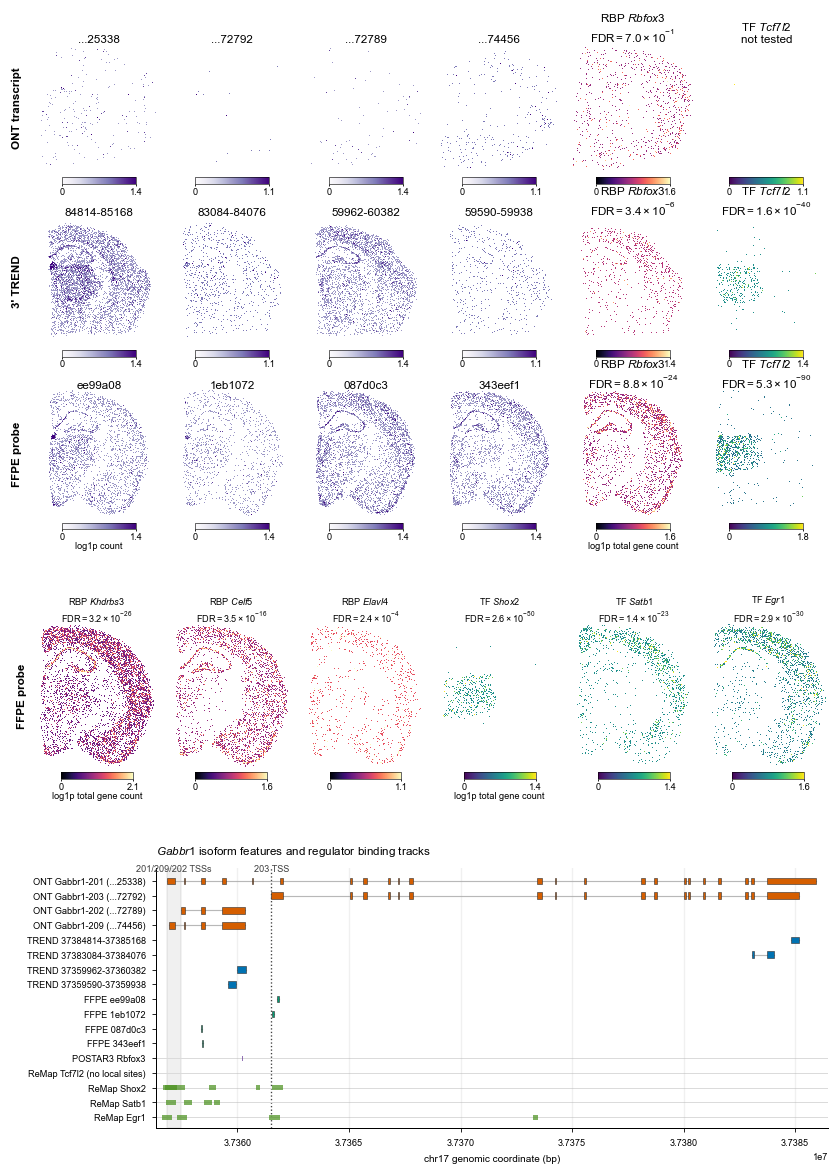

In [17]:
# Final Gabbr1 DU/regulator figure; selected features stay in the biologically inspected order.


GABBR1_SELECTED_RBP = "Rbfox3"
GABBR1_SELECTED_TF = "Tcf7l2"
GABBR1_CHROM = "chr17"
GABBR1_POSTAR_MM10_TO_MM39 = 310892
GABBR1_TSS = {
    "201": 37356858,
    "209": 37356920,
    "202": 37357460,
    "203": 37361523,
}
GABBR1_FEATURES = {
    "ffpe_probe": ["Gabbr1|ee99a08", "Gabbr1|1eb1072", "Gabbr1|087d0c3", "Gabbr1|343eef1"],
    "trend_3prime": [
        "Gabbr1:chr17:37384814-37385168:1",
        "Gabbr1:chr17:37383084-37384076:1",
        "Gabbr1:chr17:37359962-37360382:1",
        "Gabbr1:chr17:37359590-37359938:1",
    ],
    "ont_tx": [
        "ENSMUST00000025338",
        "ENSMUST00000172792",
        "ENSMUST00000172789",
        "ENSMUST00000174456",
    ],
}
GABBR1_RBP_BINDING_CANDIDATES = ["Rbfox3"]
GABBR1_TF_BINDING_CANDIDATES = ["Tcf7l2", "Shox2", "Satb1", "Egr1"]
GABBR1_CANDIDATE_EXPRESSION_GENES = ["Khdrbs3", "Celf5", "Elavl4", "Shox2", "Satb1", "Egr1"]
GABBR1_CANDIDATE_EXPRESSION_GROUPS = {
    "Khdrbs3": "rbp",
    "Celf5": "rbp",
    "Elavl4": "rbp",
    "Shox2": "tf",
    "Satb1": "tf",
    "Egr1": "tf",
}
GABBR1_REGULATOR_MAP_DATASETS = ["ffpe_probe"]
GABBR1_POSTAR3_GTF = Path.home() / "reference" / "POSTAR3" / "mouse.sorted.gtf"
GABBR1_COVARIATE_COLORS = {"rbp": "#6A3D9A", "tf_chip": "#4D9221"}
GABBR1_TRACK_COLORS = {"feature": "Purples", "rbp": "magma", "tf": "viridis"}


def _gabbr1_association_label(row, prefix="covariate"):
    for key in DATASET_ORDER:
        col = f"{prefix}_{key}"
        if col in row and pd.notna(row[col]):
            return str(row[col])
    return str(row.get(f"{prefix}_key", ""))


def _gabbr1_associations(covariate_set, top_n=5):
    table = du_tf_shared_assoc if covariate_set == "tf_chip" else du_rbp_shared_assoc
    out = table[table["gene_key"].eq("gabbr1")].copy()
    if out.empty:
        raise ValueError(f"No Gabbr1 shared DU associations for {covariate_set!r}.")

    trend_col = "pvalue_adj_trend_3prime"
    ffpe_col = "pvalue_adj_ffpe_probe"
    out = out[(out[trend_col] <= FDR_THRESHOLD) & (out[ffpe_col] <= FDR_THRESHOLD)].copy()
    if out.empty:
        return out

    if covariate_set == "tf_chip":
        priority = ["tcf7l2", "rora", "shox2", "mef2c", "tbr1"]
        out["priority"] = (
            out["covariate_key"].map({key: i for i, key in enumerate(priority)}).fillna(999)
        )
        return out.sort_values(
            ["priority", trend_col, ffpe_col, "mean_neglogp"],
            ascending=[True, True, True, False],
        ).head(top_n)

    priority = ["rbfox3", "khdrbs3", "celf5", "elavl4", "rbms3"]
    out["priority"] = (
        out["covariate_key"].map({key: i for i, key in enumerate(priority)}).fillna(999)
    )
    return out.sort_values(
        ["priority", "n_sig_datasets", trend_col, ffpe_col, "mean_neglogp"],
        ascending=[True, False, True, True, False],
    ).head(top_n)


def _plot_gabbr1_regulator_bar(ax, table, title, selected_label, show_legend=False):
    labels = [_gabbr1_association_label(row) for _, row in table.iterrows()]
    y = np.arange(len(labels))
    height = 0.22
    xmax = 0.0
    for i, key in enumerate(DATASET_ORDER):
        col = f"pvalue_adj_{key}"
        values = minus_log10_p(table[col]) if col in table else np.full(len(labels), np.nan)
        if np.isfinite(values).any():
            xmax = max(xmax, float(np.nanmax(values)))
        ax.barh(
            y + (i - 1) * height,
            values,
            height=height,
            color=DATASET_COLORS.get(key, "0.5"),
            alpha=0.86,
            label=DATASET_LABELS.get(key, key),
        )
    threshold = float(minus_log10_p([FDR_THRESHOLD])[0])
    ax.axvline(threshold, color="0.25", linestyle="--", linewidth=0.7)
    ax.text(
        threshold + 0.12,
        0.03,
        r"FDR $\leq 0.01$",
        transform=ax.get_xaxis_transform(),
        ha="left",
        va="bottom",
        fontsize=FONT_CONFIG["text"],
        color="0.25",
    )
    ax.set_title(title)
    ax.set_xlabel(r"$-\log_{10}(\mathrm{FDR})$ (DU)", labelpad=2)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    for tick in ax.get_yticklabels():
        tick.set_fontstyle("italic")
    ax.set_xlim(0, max(1.0, xmax * 1.08))
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.22)
    if show_legend:
        ax.legend(
            frameon=False,
            fontsize=FONT_CONFIG["text"],
            loc="upper right",
            bbox_to_anchor=(1.0, 1.16),
            ncol=3,
            columnspacing=0.65,
            handlelength=1.2,
        )


def _gabbr1_short_feature_label(feature):
    text = str(feature)
    if text.startswith("ENSMUST"):
        return f"...{text[-5:]}"
    if "|" in text:
        return text.split("|")[-1]
    parts = text.split(":")
    if len(parts) >= 4:
        interval = parts[2]
        if "-" in interval:
            start, end = interval.split("-", 1)
            return f"{start[-5:]}-{end[-5:]}"
        return interval
    return text


def _gabbr1_feature_image(dataset_key, feature):
    return spatial_feature_image(sdata_cache, dataset_key, feature)


def _gabbr1_gene_expression_image(dataset_key, gene):
    return spatial_gene_expression_image(sdata_cache, dataset_key, gene, max_features=40)


def _gabbr1_du_fdr_label(gene, dataset_key):
    df = du_regulator_results[dataset_key]
    hit = df[df["gene_key"].eq("gabbr1") & df["covariate_key"].eq(normalize_gene_symbol(gene))]
    if hit.empty:
        return "not tested"
    return _format_fdr(hit["pvalue_adj"].iloc[0])


def _collect_gabbr1_map_records(rbp_label, tf_label):
    records = []
    for dataset_key in DATASET_ORDER:
        for slot, feature in enumerate(GABBR1_FEATURES[dataset_key]):
            image, title = _gabbr1_feature_image(dataset_key, feature)
            records.append(
                {
                    "dataset_key": dataset_key,
                    "slot": slot,
                    "title": title,
                    "image": image,
                    "cmap": GABBR1_TRACK_COLORS["feature"],
                    "cbar_label": "log1p count",
                    "dilate": True,
                }
            )
        for offset, (gene, label, cmap) in enumerate(
            [
                (rbp_label, "RBP", GABBR1_TRACK_COLORS["rbp"]),
                (tf_label, "TF", GABBR1_TRACK_COLORS["tf"]),
            ]
        ):
            image, _ = _gabbr1_gene_expression_image(dataset_key, gene)
            records.append(
                {
                    "dataset_key": dataset_key,
                    "slot": 4 + offset,
                    "title": rf"{label} $\mathit{{{gene}}}$"
                    + f"\n{_gabbr1_du_fdr_label(gene, dataset_key)}",
                    "image": image,
                    "cmap": cmap,
                    "cbar_label": "log1p total gene count",
                    "dilate": False,
                }
            )
    for record in records:
        record["prepared_image"] = prepare_spatial_map_image(
            record["image"],
            dilate=record.get("dilate", False),
            margin=10 if record.get("dilate") else 6,
        )
    target_shape = (
        max(r["prepared_image"].shape[0] for r in records),
        max(r["prepared_image"].shape[1] for r in records),
    )
    return records, target_shape


def _plot_gabbr1_map(fig, ax, cax, record, target_shape, dataset_label=False):
    cmap = plt.get_cmap(record["cmap"]).copy()
    cmap.set_bad("white")
    image = pad_spatial_image_to_shape(record.get("prepared_image"), target_shape)
    positive = image[np.isfinite(image) & (image > 0)]
    vmax = float(np.nanpercentile(positive, 99.5)) if len(positive) else 1.0
    vmax = max(vmax, 0.25)
    im = ax.imshow(image, cmap=cmap, vmin=0.0, vmax=vmax, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(record["title"], fontsize=FONT_CONFIG["title"], pad=1.0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if dataset_label:
        ax.text(
            -0.12,
            0.5,
            DATASET_LABELS.get(record["dataset_key"], record["dataset_key"]),
            transform=ax.transAxes,
            ha="right",
            va="center",
            fontsize=FONT_CONFIG["title"],
            fontweight="bold",
            rotation=90,
        )
    shrink_colorbar_axis(cax, width=0.60)
    cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
    cbar.set_ticks([0, vmax])
    cbar.set_ticklabels(["0", format_colorbar_tick(vmax)])
    cbar.ax.tick_params(labelsize=FONT_CONFIG["text"], length=1.0, pad=1)
    cbar.outline.set_linewidth(0.35)
    label = record["cbar_label"]
    if label == "log1p total gene count" and (
        record.get("slot") != 4 or record.get("dataset_key") != "ffpe_probe"
    ):
        label = ""
    if label == "log1p count" and (
        record.get("slot") != 0 or record.get("dataset_key") != "ffpe_probe"
    ):
        label = ""
    cbar.set_label(label, fontsize=FONT_CONFIG["text"], labelpad=0)


def _plot_gabbr1_spatial_row(fig, row_spec, records, target_shape, dataset_key):
    sub = row_spec.subgridspec(2, 6, height_ratios=[1, 0.05], wspace=0.08, hspace=0.04)
    row_records = sorted(
        [record for record in records if record["dataset_key"] == dataset_key],
        key=lambda record: record["slot"],
    )
    for slot in range(6):
        ax = fig.add_subplot(sub[0, slot])
        cax = fig.add_subplot(sub[1, slot])
        _plot_gabbr1_map(fig, ax, cax, row_records[slot], target_shape, dataset_label=(slot == 0))


def _gabbr1_feature_match(row, feature):
    return row["name"] == feature or row["label"] == feature or str(feature) in row["name"]


def _gabbr1_selected_structure_rows():
    cache = reference_cache
    rows = []
    for tx_id in GABBR1_FEATURES["ont_tx"]:
        ref = cache["reference"]["by_tx"].get(tx_id)
        if ref is None:
            raise KeyError(f"Missing reference annotation for selected transcript {tx_id!r}.")
        rows.append(
            {
                "group": "ONT transcripts",
                "label": f"ONT {ref['tx_name']} (...{tx_id[-5:]})",
                "blocks": sorted(ref["blocks"]),
                "color": DATASET_COLORS["ont_tx"],
            }
        )
    for feature in GABBR1_FEATURES["trend_3prime"]:
        match = next((row for row in cache["trend"] if _gabbr1_feature_match(row, feature)), None)
        if match is None:
            raise KeyError(f"Missing reference annotation for selected TREND feature {feature!r}.")
        rows.append(
            {
                "group": "3' TREND peaks",
                "label": f"TREND {feature.split(':')[2]}",
                "blocks": sorted(match["blocks"]),
                "color": DATASET_COLORS["trend_3prime"],
            }
        )
    for feature in GABBR1_FEATURES["ffpe_probe"]:
        match = next((row for row in cache["probe"] if _gabbr1_feature_match(row, feature)), None)
        if match is None:
            raise KeyError(f"Missing reference annotation for selected probe {feature!r}.")
        rows.append(
            {
                "group": "FFPE probes",
                "label": f"FFPE {feature.split('|')[-1]}",
                "blocks": sorted(match["blocks"]),
                "color": DATASET_COLORS["ffpe_probe"],
            }
        )
    return rows


def _gabbr1_attr_value(attr_text, key):
    match = re.search(rf'{re.escape(key)} "?([^";]+)', str(attr_text))
    return match.group(1).strip().strip('"') if match else ""


def _gabbr1_postar3_sites(chrom, start, end, rbp_symbols):
    target_keys = {normalize_gene_symbol(symbol) for symbol in rbp_symbols}
    mm10_start = int(start) - GABBR1_POSTAR_MM10_TO_MM39
    mm10_end = int(end) - GABBR1_POSTAR_MM10_TO_MM39
    rows = []
    with open(GABBR1_POSTAR3_GTF, encoding="utf-8") as handle:
        seen_chrom = False
        for line in handle:
            if line.startswith("#"):
                continue
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 9:
                continue
            row_chrom, row_start, row_end = fields[0], int(fields[3]), int(fields[4])
            if row_chrom != chrom:
                if seen_chrom:
                    break
                continue
            seen_chrom = True
            if row_start > mm10_end:
                break
            if row_end < mm10_start:
                continue
            rbp = _gabbr1_attr_value(fields[8], "gene_id")
            if normalize_gene_symbol(rbp) not in target_keys:
                continue
            rows.append(
                {
                    "start": max(row_start, mm10_start) + GABBR1_POSTAR_MM10_TO_MM39,
                    "end": min(row_end, mm10_end) + GABBR1_POSTAR_MM10_TO_MM39,
                    "symbol": rbp,
                    "source": fields[1],
                }
            )
    return pd.DataFrame(rows)


def _gabbr1_remap_sites(chrom, start, end, tf_symbols):
    sites = remap_binding_sites(chrom, int(start), int(end), targets=tf_symbols)
    if sites.empty:
        return pd.DataFrame(columns=["start", "end", "symbol", "source"])
    return sites.rename(columns={"tf_symbol": "symbol"})[
        ["start", "end", "symbol", "source"]
    ].copy()


def _draw_gabbr1_structure_blocks(ax, y, row):
    blocks = sorted(row["blocks"])
    ax.plot(
        [min(s for s, _ in blocks), max(e for _, e in blocks)],
        [y, y],
        color="0.72",
        linewidth=0.7,
        zorder=1,
    )
    for start, end in blocks:
        ax.barh(
            y,
            end - start,
            left=start,
            height=0.45,
            color=row["color"],
            edgecolor="0.2",
            linewidth=0.35,
            zorder=2,
        )


def _draw_gabbr1_binding_track(ax, y, x_min, x_max, sites, color):
    ax.plot([x_min, x_max], [y, y], color="0.86", linewidth=0.6, zorder=1)
    if sites.empty:
        return
    for _, site in sites.iterrows():
        start = max(float(site["start"]), x_min)
        end = min(float(site["end"]), x_max)
        if end <= start:
            end = start + max(10, (x_max - x_min) * 0.001)
        ax.barh(
            y,
            end - start,
            left=start,
            height=0.35,
            color=color,
            edgecolor="none",
            alpha=0.72,
            zorder=2,
        )


def _plot_gabbr1_tss_markers(ax, y_min, y_max):
    p1_start = min(GABBR1_TSS[key] for key in ["201", "209", "202"])
    p1_end = max(GABBR1_TSS[key] for key in ["201", "209", "202"])
    ax.axvspan(p1_start, p1_end, color="0.25", alpha=0.08, zorder=0)
    ax.axvline(GABBR1_TSS["203"], color="0.25", linestyle=":", linewidth=0.8, zorder=0)
    ax.text(
        (p1_start + p1_end) / 2,
        y_min - 0.55,
        "201/209/202 TSSs",
        ha="center",
        va="top",
        fontsize=FONT_CONFIG["text"],
        color="0.25",
    )
    ax.text(
        GABBR1_TSS["203"],
        y_min - 0.55,
        "203 TSS",
        ha="center",
        va="top",
        fontsize=FONT_CONFIG["text"],
        color="0.25",
    )


def _plot_gabbr1_structure(ax, rbp_symbols, tf_symbols):
    feature_rows = _gabbr1_selected_structure_rows()
    plot_start = min(start for row in feature_rows for start, _ in row["blocks"])
    plot_end = max(end for row in feature_rows for _, end in row["blocks"])
    pad = max(200, int((plot_end - plot_start) * 0.018))
    x_min = plot_start - pad
    x_max = plot_end + pad
    rbp_sites = _gabbr1_postar3_sites(GABBR1_CHROM, x_min, x_max, rbp_symbols)
    tf_sites = _gabbr1_remap_sites(GABBR1_CHROM, x_min, x_max, tf_symbols)

    y_labels = []
    for y, row in enumerate(feature_rows):
        _draw_gabbr1_structure_blocks(ax, y, row)
        y_labels.append(row["label"])

    y = len(feature_rows)
    for rbp in rbp_symbols:
        sites = rbp_sites[
            rbp_sites["symbol"].map(normalize_gene_symbol).eq(normalize_gene_symbol(rbp))
        ]
        label = f"POSTAR3 {rbp}" + (" (no local sites)" if sites.empty else "")
        _draw_gabbr1_binding_track(ax, y, x_min, x_max, sites, GABBR1_COVARIATE_COLORS["rbp"])
        y_labels.append(label)
        y += 1
    for tf in tf_symbols:
        sites = tf_sites[
            tf_sites["symbol"].map(normalize_gene_symbol).eq(normalize_gene_symbol(tf))
        ]
        label = f"ReMap {tf}" + (" (no local sites)" if sites.empty else "")
        _draw_gabbr1_binding_track(ax, y, x_min, x_max, sites, GABBR1_COVARIATE_COLORS["tf_chip"])
        y_labels.append(label)
        y += 1

    _plot_gabbr1_tss_markers(ax, -0.55, y - 0.2)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-0.9, y - 0.25)
    ax.set_yticks(np.arange(len(y_labels)))
    ax.set_yticklabels(y_labels, fontsize=FONT_CONFIG["tick"])
    ax.invert_yaxis()
    ax.set_xlabel(f"{GABBR1_CHROM} genomic coordinate (bp)")
    ax.set_title(
        r"$\mathit{Gabbr1}$ isoform features and regulator binding tracks", loc="left", pad=8
    )
    ax.grid(axis="x", alpha=0.18)
    # Track identities are already encoded by row labels; omit the legend to avoid overlap.


def _gabbr1_ffpe_du_label(gene):
    df = du_regulator_results["ffpe_probe"]
    hit = df[df["gene_key"].eq("gabbr1") & df["covariate_key"].eq(normalize_gene_symbol(gene))]
    if hit.empty:
        return "not tested"
    p = float(hit["pvalue_adj"].iloc[0])
    return _format_fdr(p)


def _collect_gabbr1_regulator_expression_records(genes):
    records = []
    for gene in genes:
        for dataset_key in GABBR1_REGULATOR_MAP_DATASETS:
            image, _ = _gabbr1_gene_expression_image(dataset_key, gene)
            records.append({"gene": gene, "dataset_key": dataset_key, "image": image})
    return records


def _plot_gabbr1_regulator_expression_row(fig, row_spec, genes):
    records = _collect_gabbr1_regulator_expression_records(genes)
    valid_images = [record["image"] for record in records]
    target_shape = (
        max(img.shape[0] for img in valid_images),
        max(img.shape[1] for img in valid_images),
    )
    sub = row_spec.subgridspec(2, len(genes), height_ratios=[1, 0.055], wspace=0.12, hspace=0.06)
    for col, gene in enumerate(genes):
        ax = fig.add_subplot(sub[0, col])
        cax = fig.add_subplot(sub[1, col])
        record = next(r for r in records if r["gene"] == gene and r["dataset_key"] == "ffpe_probe")
        image = pad_spatial_image_to_shape(record["image"], target_shape)
        values = image[np.isfinite(image)]
        vmax = float(np.nanpercentile(values[values > 0], 99.0)) if np.any(values > 0) else 1.0
        vmax = max(vmax, 0.25)
        group = GABBR1_CANDIDATE_EXPRESSION_GROUPS.get(gene, "rbp")
        cmap_name = GABBR1_TRACK_COLORS["rbp"] if group == "rbp" else GABBR1_TRACK_COLORS["tf"]
        cmap = plt.get_cmap(cmap_name).copy()
        cmap.set_bad("white")
        im = ax.imshow(image, cmap=cmap, vmin=0.0, vmax=vmax, interpolation="nearest")
        label_prefix = "RBP" if group == "rbp" else "TF"
        ax.set_title(
            rf"{label_prefix} $\mathit{{{gene}}}$" + f"\n{_gabbr1_ffpe_du_label(gene)}",
            fontsize=FONT_CONFIG["text"],
            pad=1.0,
        )
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if col == 0:
            ax.text(
                -0.12,
                0.5,
                "FFPE probe",
                transform=ax.transAxes,
                ha="right",
                va="center",
                fontsize=FONT_CONFIG["title"],
                fontweight="bold",
                rotation=90,
            )
        shrink_colorbar_axis(cax, width=0.60)
        cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
        cbar.set_ticks([0, vmax])
        cbar.set_ticklabels(["0", format_colorbar_tick(vmax)])
        cbar.ax.tick_params(labelsize=FONT_CONFIG["text"], length=1.0, pad=1)
        cbar.outline.set_linewidth(0.35)
        cbar_label = "log1p total gene count" if col in (0, 3) else ""
        cbar.set_label(cbar_label, fontsize=FONT_CONFIG["text"], labelpad=0)


with plt.rc_context(
    {
        "font.size": FONT_CONFIG["font"],
        "axes.titlesize": FONT_CONFIG["title"],
        "axes.labelsize": FONT_CONFIG["label"],
        "xtick.labelsize": FONT_CONFIG["tick"],
        "ytick.labelsize": FONT_CONFIG["tick"],
        "legend.fontsize": FONT_CONFIG["legend"],
        "legend.title_fontsize": FONT_CONFIG["legend"],
    }
):
    rbp_label = GABBR1_SELECTED_RBP
    tf_label = GABBR1_SELECTED_TF
    map_records, map_shape = _collect_gabbr1_map_records(rbp_label, tf_label)

    fig = plt.figure(figsize=(MAX_FIGURE_WIDTH_IN, 9.95))
    grid = fig.add_gridspec(
        7,
        20,
        height_ratios=[0.86, 0.86, 0.86, 0.20, 0.94, 0.16, 1.58],
        hspace=0.24,
        wspace=0.0,
    )
    fig.subplots_adjust(left=0.080, right=0.985, top=0.965, bottom=0.055)

    for row_idx, dataset_key in enumerate(DATASET_ORDER):
        _plot_gabbr1_spatial_row(fig, grid[row_idx, :], map_records, map_shape, dataset_key)

    for spacer_row in [3, 5]:
        spacer_ax = fig.add_subplot(grid[spacer_row, :])
        spacer_ax.axis("off")

    _plot_gabbr1_regulator_expression_row(fig, grid[4, :], GABBR1_CANDIDATE_EXPRESSION_GENES)
    _plot_gabbr1_structure(
        fig.add_subplot(grid[6, 3:]),
        GABBR1_RBP_BINDING_CANDIDATES,
        GABBR1_TF_BINDING_CANDIDATES,
    )

    save_pdf(fig, "gabbr1_du_regulator_summary.pdf")
    plt.show()